In [1]:
# CELL 1 — INSTALL COMPATIBLE PACKAGE VERSIONS
# This repairs the environment after incompatible upgrades.

%pip install -q --upgrade --force-reinstall \
    "numpy==1.26.4" \
    "scipy==1.13.1" \
    "pandas==2.2.3" \
    "packaging==24.2" \
    "scikit-learn==1.5.2" \
    "statsmodels==0.14.4" \
    "matplotlib==3.9.2" \
    "openpyxl==3.1.5" \
    "joblib==1.4.2"

%pip install -q \
    GEOparse \
    gseapy

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
scikit-survival 0.28.0 requires numpy>=2.0.0, but you have numpy 1.26.4 which is incompatible.
scikit-survival 0.28.0 requires scikit-learn<1.10,>=1.9.0, but you have scikit-learn 1.5.2 which is incompatible.
fast-array-utils 1.5 requires numpy>=2, but you have numpy 1.26.4 which is incompatible.
streamlit 1.37.1 requires pillow<11,>=7.1.0, but you have pillow 12.3.0 which is incompatible.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [60]:
# CELL 1B — VERIFY PACKAGE COMPATIBILITY

import numpy as np
import scipy
import pandas as pd
import sklearn
import statsmodels
import matplotlib
import packaging
import GEOparse
import gseapy as gp

print("PACKAGE VERSION CHECK")
print("=" * 45)
print("numpy        :", np.__version__)
print("scipy        :", scipy.__version__)
print("pandas       :", pd.__version__)
print("scikit-learn :", sklearn.__version__)
print("statsmodels  :", statsmodels.__version__)
print("matplotlib   :", matplotlib.__version__)
print("packaging    :", packaging.__version__)
print("GEOparse     :", getattr(GEOparse, "__version__", "installed"))
print("gseapy       :", gp.__version__)

assert np.__version__ == "1.26.4"
assert scipy.__version__ == "1.13.1"
assert pd.__version__ == "2.2.3"
assert sklearn.__version__ == "1.5.2"

print("\n✓ Core scientific environment is compatible.")
print("✓ You may continue to Cell 2.")

PACKAGE VERSION CHECK
numpy        : 1.26.4
scipy        : 1.13.1
pandas       : 2.2.3
scikit-learn : 1.5.2
statsmodels  : 0.14.4
matplotlib   : 3.9.2
packaging    : 25.0
GEOparse     : 2.0.4
gseapy       : 1.3.1

✓ Core scientific environment is compatible.
✓ You may continue to Cell 2.


In [3]:
# CELL 2 — IMPORTS AND GLOBAL CONFIGURATION

from pathlib import Path
import json
import re
import sys
import warnings
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import (
    mannwhitneyu,
    chi2_contingency,
    fisher_exact
)

from statsmodels.stats.multitest import multipletests
import statsmodels.api as sm

from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    adjusted_rand_score,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
    silhouette_score
)
from sklearn.model_selection import (
    GridSearchCV,
    RepeatedStratifiedKFold,
    StratifiedKFold,
    cross_val_predict,
    permutation_test_score
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

import joblib
import GEOparse
import gseapy as gp

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

GSE_ID = "GSE104580"
GPL_ID = "GPL570"

BASE_DIR = Path.cwd() / "IGET2026_GSE104580"
DATA_DIR = BASE_DIR / "data"
RESULTS_DIR = BASE_DIR / "results"
FIGURES_DIR = BASE_DIR / "figures"
MODELS_DIR = BASE_DIR / "models"

for folder in [BASE_DIR, DATA_DIR, RESULTS_DIR, FIGURES_DIR, MODELS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "figure.constrained_layout.use": True
})

print("Project directory:", BASE_DIR)
print("Python:", sys.version.split()[0])
print("Operating system:", platform.platform())
print("GEOparse:", GEOparse.__version__ if hasattr(GEOparse, "__version__") else "installed")
print("GSEApy:", gp.__version__)

Project directory: /Users/rifaldyfajar/IGET2026_GSE104580
Python: 3.12.7
Operating system: macOS-26.3-arm64-arm-64bit
GEOparse: 2.0.4
GSEApy: 1.3.1


In [5]:
# CELL 2 — IMPORTS AND GLOBAL CONFIGURATION

from pathlib import Path
import json
import re
import sys
import warnings
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import (
    mannwhitneyu,
    chi2_contingency,
    fisher_exact
)

from statsmodels.stats.multitest import multipletests
import statsmodels.api as sm

from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    adjusted_rand_score,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
    silhouette_score
)
from sklearn.model_selection import (
    GridSearchCV,
    RepeatedStratifiedKFold,
    StratifiedKFold,
    cross_val_predict,
    permutation_test_score
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

import joblib
import GEOparse
import gseapy as gp

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

GSE_ID = "GSE104580"
GPL_ID = "GPL570"

BASE_DIR = Path.cwd() / "IGET2026_GSE104580"
DATA_DIR = BASE_DIR / "data"
RESULTS_DIR = BASE_DIR / "results"
FIGURES_DIR = BASE_DIR / "figures"
MODELS_DIR = BASE_DIR / "models"

for folder in [BASE_DIR, DATA_DIR, RESULTS_DIR, FIGURES_DIR, MODELS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "figure.constrained_layout.use": True
})

print("Project directory:", BASE_DIR)
print("Python:", sys.version.split()[0])
print("Operating system:", platform.platform())
print("GEOparse:", GEOparse.__version__ if hasattr(GEOparse, "__version__") else "installed")
print("GSEApy:", gp.__version__)

Project directory: /Users/rifaldyfajar/IGET2026_GSE104580
Python: 3.12.7
Operating system: macOS-26.3-arm64-arm-64bit
GEOparse: 2.0.4
GSEApy: 1.3.1


In [9]:
# CELL 3 — ROBUST DOWNLOAD AND LOAD OF GSE104580
# Replaces the previous Cell 3 completely.

from pathlib import Path
import gzip
import shutil
import urllib.request
import time

GSE_SOFT_URL = (
    "https://ftp.ncbi.nlm.nih.gov/geo/series/"
    "GSE104nnn/GSE104580/soft/GSE104580_family.soft.gz"
)

SOFT_GZ_PATH = DATA_DIR / "GSE104580_family.soft.gz"
TEMP_PATH = DATA_DIR / "GSE104580_family.soft.gz.part"


def validate_gzip_file(file_path):
    """
    Confirm that a gzip file is structurally readable.
    Reads through the entire compressed stream without extracting it.
    """
    try:
        with gzip.open(file_path, "rb") as handle:
            while handle.read(1024 * 1024):
                pass
        return True
    except Exception as error:
        print("Gzip validation failed:", error)
        return False


def download_with_progress(url, destination, max_retries=3):
    """
    Download a file through HTTPS with progress reporting and retries.
    """
    for attempt in range(1, max_retries + 1):
        try:
            if destination.exists():
                destination.unlink()

            print(f"Download attempt {attempt}/{max_retries}")
            print("Source:", url)

            request = urllib.request.Request(
                url,
                headers={"User-Agent": "Mozilla/5.0"}
            )

            with urllib.request.urlopen(
                request,
                timeout=120
            ) as response, open(destination, "wb") as output:

                total_size = response.headers.get("Content-Length")
                total_size = (
                    int(total_size)
                    if total_size is not None
                    else None
                )

                downloaded = 0
                chunk_size = 1024 * 1024

                while True:
                    chunk = response.read(chunk_size)

                    if not chunk:
                        break

                    output.write(chunk)
                    downloaded += len(chunk)

                    if total_size:
                        percent = 100 * downloaded / total_size
                        print(
                            f"\rDownloaded: "
                            f"{downloaded / 1024**2:.1f} MB "
                            f"of {total_size / 1024**2:.1f} MB "
                            f"({percent:.1f}%)",
                            end=""
                        )
                    else:
                        print(
                            f"\rDownloaded: "
                            f"{downloaded / 1024**2:.1f} MB",
                            end=""
                        )

            print()

            if total_size is not None:
                actual_size = destination.stat().st_size

                if actual_size != total_size:
                    raise IOError(
                        f"Size mismatch: expected {total_size} bytes, "
                        f"received {actual_size} bytes."
                    )

            print(
                "Download completed:",
                f"{destination.stat().st_size / 1024**2:.1f} MB"
            )

            return

        except Exception as error:
            print(f"\nAttempt {attempt} failed:", error)

            if destination.exists():
                destination.unlink()

            if attempt == max_retries:
                raise RuntimeError(
                    "The GEO file could not be downloaded after "
                    f"{max_retries} attempts."
                ) from error

            print("Waiting 5 seconds before retrying...")
            time.sleep(5)


print("Preparing GSE104580 family SOFT file...")

# Remove the corrupted/partial file produced by the earlier attempt.
for file_path in [SOFT_GZ_PATH, TEMP_PATH]:
    if file_path.exists():
        print(
            "Removing previous incomplete file:",
            file_path.name,
            f"({file_path.stat().st_size / 1024**2:.1f} MB)"
        )
        file_path.unlink()

# Download into a temporary filename first.
download_with_progress(
    url=GSE_SOFT_URL,
    destination=TEMP_PATH,
    max_retries=3
)

print("\nValidating downloaded gzip archive...")

if not validate_gzip_file(TEMP_PATH):
    TEMP_PATH.unlink(missing_ok=True)
    raise RuntimeError(
        "The downloaded file is incomplete or corrupted. "
        "Run this Cell 3 again using a stable connection."
    )

print("Gzip validation PASSED.")

# Rename only after successful validation.
TEMP_PATH.replace(SOFT_GZ_PATH)

print("\nLoading validated local file with GEOparse...")

gse = GEOparse.get_GEO(
    filepath=str(SOFT_GZ_PATH),
    destdir=str(DATA_DIR),
    annotate_gpl=True,
    silent=False
)

print("\nConstructing probe-level expression matrix...")

expression_probe = gse.pivot_samples("VALUE")

expression_probe.index = expression_probe.index.astype(str)
expression_probe.columns = expression_probe.columns.astype(str)

expression_probe = expression_probe.apply(
    pd.to_numeric,
    errors="coerce"
)

print("\nGSE104580 LOAD SUMMARY")
print("=" * 45)
print("Probe-level expression shape:", expression_probe.shape)
print("Number of samples:", expression_probe.shape[1])
print("Number of probes:", expression_probe.shape[0])
print(
    "Missing expression values:",
    int(expression_probe.isna().sum().sum())
)

assert expression_probe.shape[1] == 147, (
    f"Expected 147 samples, but found "
    f"{expression_probe.shape[1]}."
)

assert expression_probe.shape[0] > 50000, (
    "Unexpectedly few GPL570 probes were loaded."
)

expression_probe.to_pickle(
    DATA_DIR / "GSE104580_probe_expression.pkl"
)

expression_probe.to_csv(
    DATA_DIR / "GSE104580_probe_expression.csv.gz",
    compression="gzip"
)

print("\n✓ GSE104580 downloaded and loaded successfully.")
print("✓ Expected 147 samples were found.")
print("✓ You may continue to Cell 4.")

display(expression_probe.iloc[:5, :5])

Preparing GSE104580 family SOFT file...
Download attempt 1/3
Source: https://ftp.ncbi.nlm.nih.gov/geo/series/GSE104nnn/GSE104580/soft/GSE104580_family.soft.gz
Downloaded: 59.8 MB of 59.8 MB (100.0%)
Download completed: 59.8 MB

Validating downloaded gzip archive...


03-Aug-2026 20:03:31 INFO GEOparse - Parsing /Users/rifaldyfajar/IGET2026_GSE104580/data/GSE104580_family.soft.gz: 
03-Aug-2026 20:03:31 DEBUG GEOparse - DATABASE: GeoMiame
03-Aug-2026 20:03:31 DEBUG GEOparse - SERIES: GSE104580
03-Aug-2026 20:03:31 DEBUG GEOparse - PLATFORM: GPL570


Gzip validation PASSED.

Loading validated local file with GEOparse...


03-Aug-2026 20:03:32 DEBUG GEOparse - SAMPLE: GSM2803655
03-Aug-2026 20:03:32 DEBUG GEOparse - SAMPLE: GSM2803656
03-Aug-2026 20:03:32 DEBUG GEOparse - SAMPLE: GSM2803657
03-Aug-2026 20:03:32 DEBUG GEOparse - SAMPLE: GSM2803658
03-Aug-2026 20:03:32 DEBUG GEOparse - SAMPLE: GSM2803659
03-Aug-2026 20:03:32 DEBUG GEOparse - SAMPLE: GSM2803660
03-Aug-2026 20:03:33 DEBUG GEOparse - SAMPLE: GSM2803661
03-Aug-2026 20:03:33 DEBUG GEOparse - SAMPLE: GSM2803662
03-Aug-2026 20:03:33 DEBUG GEOparse - SAMPLE: GSM2803663
03-Aug-2026 20:03:33 DEBUG GEOparse - SAMPLE: GSM2803664
03-Aug-2026 20:03:33 DEBUG GEOparse - SAMPLE: GSM2803665
03-Aug-2026 20:03:33 DEBUG GEOparse - SAMPLE: GSM2803666
03-Aug-2026 20:03:33 DEBUG GEOparse - SAMPLE: GSM2803667
03-Aug-2026 20:03:33 DEBUG GEOparse - SAMPLE: GSM2803668
03-Aug-2026 20:03:33 DEBUG GEOparse - SAMPLE: GSM2803669
03-Aug-2026 20:03:33 DEBUG GEOparse - SAMPLE: GSM2803670
03-Aug-2026 20:03:33 DEBUG GEOparse - SAMPLE: GSM2803671
03-Aug-2026 20:03:33 DEBUG GEOp


Constructing probe-level expression matrix...

GSE104580 LOAD SUMMARY
Probe-level expression shape: (54675, 147)
Number of samples: 147
Number of probes: 54675
Missing expression values: 0

✓ GSE104580 downloaded and loaded successfully.
✓ Expected 147 samples were found.
✓ You may continue to Cell 4.


name,GSM2803655,GSM2803656,GSM2803657,GSM2803658,GSM2803659
ID_REF,,,,,
1007_s_at,10.48360,7.76572,6.69591,9.60446,5.70717
1053_at,7.53510,7.10266,8.22136,8.18912,8.30439
117_at,5.99159,6.25151,6.39488,7.34129,5.37509
121_at,5.83643,5.91164,6.01978,6.07487,7.02020
1255_g_at,2.39292,2.40909,2.53837,2.44745,2.51321


Label counts:
response
Responder       81
Nonresponder    66
Name: count, dtype: int64

Responders: 81
Nonresponders: 66

Phenotype verification PASSED: 81 responders and 66 nonresponders.


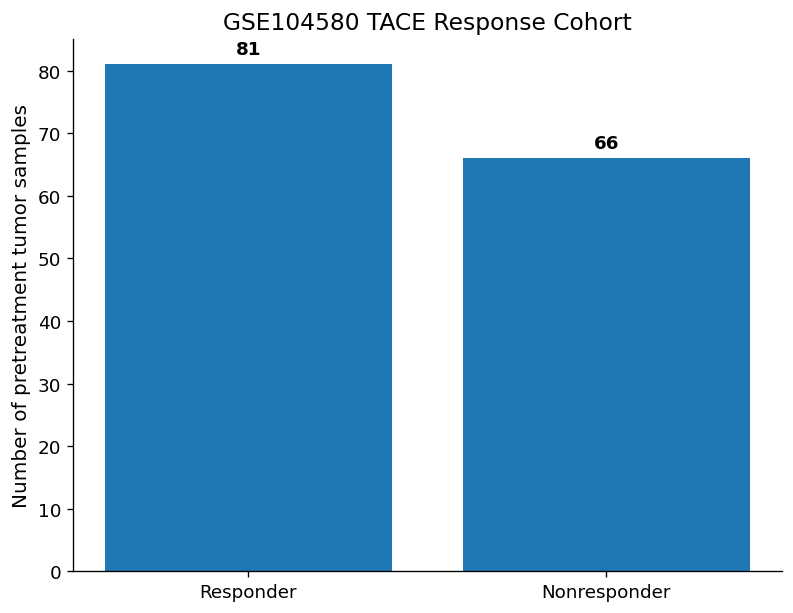

,title,source_name,characteristics,description,response,response_binary
name,,,,,,
GSM2803655,TACE_Response_1,Tissue RNA sample from HCC TACE_Response patient,subject status: hepatocellular carcinoma (HCC)...,Gene expression data from HCC Tissue sample of...,Responder,1
GSM2803656,TACE_Response_2,Tissue RNA sample from HCC TACE_Response patient,subject status: hepatocellular carcinoma (HCC)...,Gene expression data from HCC Tissue sample of...,Responder,1
GSM2803657,TACE_Response_3,Tissue RNA sample from HCC TACE_Response patient,subject status: hepatocellular carcinoma (HCC)...,Gene expression data from HCC Tissue sample of...,Responder,1
GSM2803658,TACE_Response_5,Tissue RNA sample from HCC TACE_Response patient,subject status: hepatocellular carcinoma (HCC)...,Gene expression data from HCC Tissue sample of...,Responder,1
GSM2803659,TACE_Response_6,Tissue RNA sample from HCC TACE_Response patient,subject status: hepatocellular carcinoma (HCC)...,Gene expression data from HCC Tissue sample of...,Responder,1


In [11]:
# CELL 4 — BUILD SAMPLE METADATA AND RESPONSE LABELS

def flatten_metadata_value(value):
    """Convert GEO metadata values into one searchable string."""
    if value is None:
        return ""
    if isinstance(value, (list, tuple)):
        return " | ".join(map(str, value))
    return str(value)


metadata_rows = []

for gsm_id, gsm in gse.gsms.items():
    md = gsm.metadata

    searchable_fields = {
        "title": flatten_metadata_value(md.get("title", "")),
        "source_name": flatten_metadata_value(md.get("source_name_ch1", "")),
        "characteristics": flatten_metadata_value(md.get("characteristics_ch1", "")),
        "description": flatten_metadata_value(md.get("description", ""))
    }

    combined_text = " | ".join(searchable_fields.values()).lower()

    # Non-response must be checked BEFORE response because
    # the word "response" also occurs within "non-response".
    if re.search(r"non[\s_-]*(response|responder)", combined_text):
        response_label = "Nonresponder"
        response_binary = 0
    elif re.search(r"(^|[\s_|-])(response|responder)([\s_|-]|$)", combined_text):
        response_label = "Responder"
        response_binary = 1
    else:
        response_label = np.nan
        response_binary = np.nan

    metadata_rows.append({
        "sample_id": gsm_id,
        **searchable_fields,
        "response": response_label,
        "response_binary": response_binary
    })


metadata = pd.DataFrame(metadata_rows).set_index("sample_id")

# Keep only samples present in the expression matrix.
metadata = metadata.reindex(expression_probe.columns)

print("Label counts:")
print(metadata["response"].value_counts(dropna=False))

# Scientific integrity checks.
assert metadata.index.equals(expression_probe.columns), \
    "Metadata and expression columns are not aligned."

assert metadata["response_binary"].notna().all(), \
    "Some samples could not be labelled. Inspect metadata before continuing."

assert metadata.shape[0] == 147, \
    f"Expected 147 samples, found {metadata.shape[0]}."

assert set(metadata["response_binary"].astype(int).unique()) == {0, 1}, \
    "The binary outcome must contain both 0 and 1."

n_responder = int((metadata["response_binary"] == 1).sum())
n_nonresponder = int((metadata["response_binary"] == 0).sum())

print(f"\nResponders: {n_responder}")
print(f"Nonresponders: {n_nonresponder}")

if (n_responder, n_nonresponder) != (81, 66):
    print(
        "\nWARNING: counts differ from the expected 81 responders and "
        "66 nonresponders. Stop and inspect the metadata."
    )
else:
    print("\nPhenotype verification PASSED: 81 responders and 66 nonresponders.")

metadata["response_binary"] = metadata["response_binary"].astype(int)
metadata.to_csv(DATA_DIR / "GSE104580_metadata.csv")

# Plot outcome distribution.
counts = metadata["response"].value_counts().reindex(
    ["Responder", "Nonresponder"]
)

fig, ax = plt.subplots(figsize=(6.5, 5))
bars = ax.bar(counts.index, counts.values)

for bar, value in zip(bars, counts.values):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        str(value),
        ha="center",
        va="bottom",
        fontweight="bold"
    )

ax.set_ylabel("Number of pretreatment tumor samples")
ax.set_title("GSE104580 TACE Response Cohort")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.savefig(
    FIGURES_DIR / "Figure_01_Response_Distribution.jpg",
    bbox_inches="tight"
)
plt.show()

display(metadata.head())

In [13]:
# CELL 5 — PROBE-TO-GENE ANNOTATION AND GENE-LEVEL EXPRESSION

# Load GPL570 if it was not included in the GSE object.
if GPL_ID in gse.gpls:
    gpl = gse.gpls[GPL_ID]
else:
    print("GPL570 annotation was not embedded; downloading it separately...")
    gpl = GEOparse.get_GEO(
        geo=GPL_ID,
        destdir=str(DATA_DIR),
        silent=False
    )

annotation = gpl.table.copy()
annotation.columns = annotation.columns.astype(str)

print("GPL annotation shape:", annotation.shape)
print("Available annotation columns:")
print(annotation.columns.tolist())

# Locate the probe identifier column.
id_candidates = [
    col for col in annotation.columns
    if col.strip().lower() in {"id", "id_ref", "probe id", "probe_id"}
]

if not id_candidates:
    raise ValueError("Could not identify the GPL570 probe ID column.")

probe_id_col = id_candidates[0]

# Locate the official gene-symbol column.
symbol_candidates = [
    col for col in annotation.columns
    if "gene symbol" in col.lower()
    or col.strip().lower() in {"symbol", "gene_symbol"}
]

if not symbol_candidates:
    raise ValueError(
        "Could not identify the gene-symbol column. "
        "Inspect annotation.columns manually."
    )

gene_symbol_col = symbol_candidates[0]

probe_map = annotation[[probe_id_col, gene_symbol_col]].copy()
probe_map.columns = ["probe_id", "gene_symbol"]

probe_map["probe_id"] = probe_map["probe_id"].astype(str)
probe_map["gene_symbol"] = probe_map["gene_symbol"].astype(str)

# GPL570 occasionally lists several symbols separated by ///.
# Use the first annotated official symbol.
probe_map["gene_symbol"] = (
    probe_map["gene_symbol"]
    .str.split(r"\s*///\s*", regex=True)
    .str[0]
    .str.strip()
    .str.upper()
)

invalid_symbols = {
    "",
    "---",
    "NAN",
    "NA",
    "NONE",
    "NULL"
}

probe_map = probe_map[
    ~probe_map["gene_symbol"].isin(invalid_symbols)
].drop_duplicates("probe_id")

# Merge expression with annotation.
expression_annotated = expression_probe.copy()
expression_annotated["probe_id"] = expression_annotated.index

expression_annotated = expression_annotated.merge(
    probe_map,
    on="probe_id",
    how="inner"
)

# Aggregate multiple probes mapping to the same gene using the median.
sample_columns = expression_probe.columns.tolist()

expression_gene = (
    expression_annotated
    .groupby("gene_symbol")[sample_columns]
    .median()
)

# Remove genes with zero variance or excessive missingness.
valid_missingness = expression_gene.isna().mean(axis=1) <= 0.10
valid_variance = expression_gene.var(axis=1, skipna=True) > 0

expression_gene = expression_gene.loc[
    valid_missingness & valid_variance
]

# Impute the rare missing value using that gene's sample median.
expression_gene = expression_gene.T
expression_gene = expression_gene.fillna(expression_gene.median())
expression_gene = expression_gene.T

assert expression_gene.columns.equals(metadata.index), \
    "Gene-expression matrix and metadata are not aligned."

print("Gene-level expression shape:", expression_gene.shape)
print("Mapped genes:", expression_gene.shape[0])
print("Samples:", expression_gene.shape[1])
print("Remaining missing values:", int(expression_gene.isna().sum().sum()))

expression_gene.to_pickle(DATA_DIR / "GSE104580_gene_expression.pkl")
expression_gene.to_csv(
    DATA_DIR / "GSE104580_gene_expression.csv.gz",
    compression="gzip"
)

display(expression_gene.iloc[:5, :5])

GPL annotation shape: (54675, 16)
Available annotation columns:
['ID', 'GB_ACC', 'SPOT_ID', 'Species Scientific Name', 'Annotation Date', 'Sequence Type', 'Sequence Source', 'Target Description', 'Representative Public ID', 'Gene Title', 'Gene Symbol', 'ENTREZ_GENE_ID', 'RefSeq Transcript ID', 'Gene Ontology Biological Process', 'Gene Ontology Cellular Component', 'Gene Ontology Molecular Function']
Gene-level expression shape: (22878, 147)
Mapped genes: 22878
Samples: 147
Remaining missing values: 0


,GSM2803655,GSM2803656,GSM2803657,GSM2803658,GSM2803659
gene_symbol,,,,,
A1BG,11.601900,12.11830,12.02250,7.230940,7.68808
A1BG-AS1,2.620170,2.64289,2.84570,2.801720,2.65561
A1CF,11.081750,11.24400,12.23730,10.242450,11.76745
A2M,7.839445,7.82583,7.59889,7.117725,6.17066
A2M-AS1,6.860250,4.95951,5.23361,4.720350,7.43142


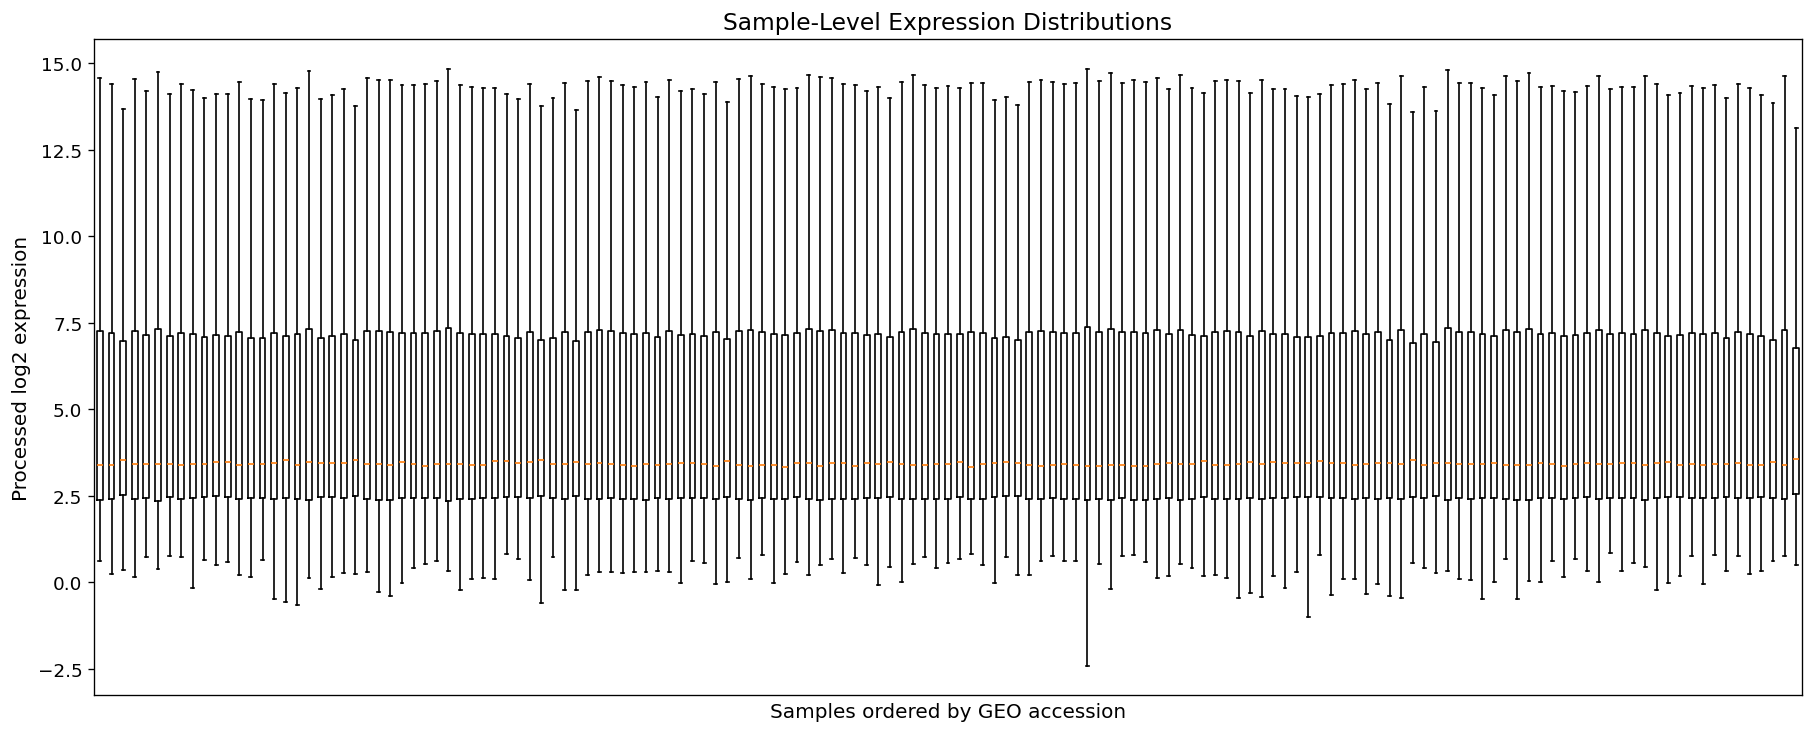

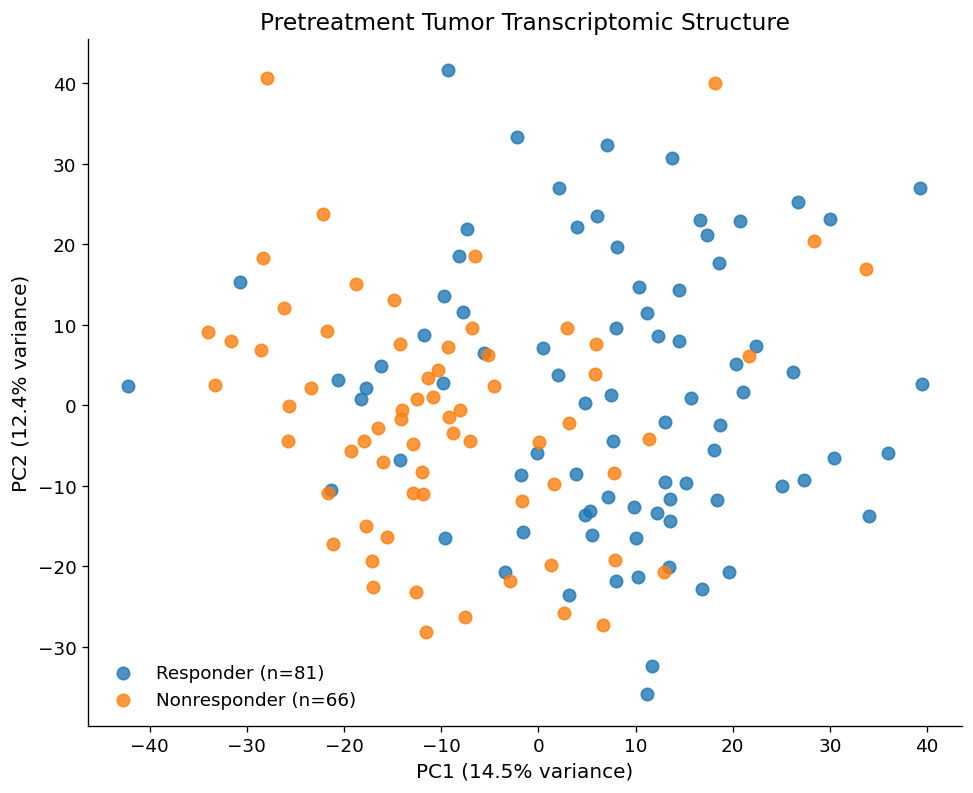

In [15]:
# CELL 6 — QUALITY CONTROL

# 6A. Per-sample expression distributions.
fig, ax = plt.subplots(figsize=(15, 6))

ax.boxplot(
    [expression_probe[col].dropna().values for col in expression_probe.columns],
    showfliers=False
)

ax.set_xlabel("Samples ordered by GEO accession")
ax.set_ylabel("Processed log2 expression")
ax.set_title("Sample-Level Expression Distributions")
ax.set_xticks([])

fig.savefig(
    FIGURES_DIR / "Figure_02_Expression_Distributions.jpg",
    bbox_inches="tight"
)
plt.show()


# 6B. PCA using the 2,000 most variable genes.
gene_variance = expression_gene.var(axis=1)
top_variable_genes = gene_variance.nlargest(
    min(2000, expression_gene.shape[0])
).index

pca_input = expression_gene.loc[top_variable_genes].T

pca_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=2, random_state=RANDOM_STATE))
])

pca_coordinates = pca_pipeline.fit_transform(pca_input)

pca_df = pd.DataFrame(
    pca_coordinates,
    index=pca_input.index,
    columns=["PC1", "PC2"]
).join(metadata[["response", "response_binary"]])

explained = pca_pipeline.named_steps["pca"].explained_variance_ratio_ * 100

fig, ax = plt.subplots(figsize=(8, 6.5))

for group_name in ["Responder", "Nonresponder"]:
    subset = pca_df[pca_df["response"] == group_name]
    ax.scatter(
        subset["PC1"],
        subset["PC2"],
        label=f"{group_name} (n={len(subset)})",
        s=55,
        alpha=0.8
    )

ax.set_xlabel(f"PC1 ({explained[0]:.1f}% variance)")
ax.set_ylabel(f"PC2 ({explained[1]:.1f}% variance)")
ax.set_title("Pretreatment Tumor Transcriptomic Structure")
ax.legend(frameon=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.savefig(
    FIGURES_DIR / "Figure_03_Gene_Expression_PCA.jpg",
    bbox_inches="tight"
)
plt.show()

pca_df.to_csv(RESULTS_DIR / "PCA_coordinates.csv")

# Do not automatically remove PCA outliers.
# Outlier exclusion must require a documented technical reason.

In [17]:
# CELL 7 — RETRIEVE AND SELECT MECHANISTIC PATHWAYS

print("Downloading the MSigDB Hallmark 2020 gene-set library...")

hallmark_library = gp.get_library(
    name="MSigDB_Hallmark_2020",
    organism="Human"
)

print("Total Hallmark terms obtained:", len(hallmark_library))


def normalize_term(text):
    """Normalize pathway names for robust matching."""
    return re.sub(r"[^A-Z0-9]+", "", str(text).upper())


# Pretreatment biological programs with a mechanistic relationship
# to ischemia, hypoxia, treatment resistance, tumor viability,
# stromal remodeling, and inflammatory signaling.
target_pathways = {
    "Hypoxia": "HYPOXIA",
    "Angiogenesis": "ANGIOGENESIS",
    "Glycolysis": "GLYCOLYSIS",
    "Oxidative phosphorylation": "OXIDATIVEPHOSPHORYLATION",
    "Epithelial-mesenchymal transition": "EPITHELIALMESENCHYMALTRANSITION",
    "DNA repair": "DNAREPAIR",
    "Apoptosis": "APOPTOSIS",
    "p53 pathway": "P53PATHWAY",
    "E2F targets": "E2FTARGETS",
    "G2M checkpoint": "G2MCHECKPOINT",
    "Inflammatory response": "INFLAMMATORYRESPONSE",
    "IL6-JAK-STAT3 signaling": "IL6JAKSTAT3SIGNALING",
    "TNF-alpha/NF-kB signaling": "TNFALPHASIGNALINGVIANFKB",
    "Complement": "COMPLEMENT"
}

selected_gene_sets = {}
selection_log = []

for clean_name, search_key in target_pathways.items():
    matches = [
        term for term in hallmark_library
        if search_key in normalize_term(term)
    ]

    if len(matches) == 0:
        selection_log.append({
            "pathway": clean_name,
            "matched_term": None,
            "status": "NOT FOUND"
        })
        continue

    matched_term = matches[0]

    genes = sorted({
        str(gene).upper().strip()
        for gene in hallmark_library[matched_term]
        if str(gene).strip()
    })

    genes_present = sorted(set(genes).intersection(expression_gene.index))

    selected_gene_sets[clean_name] = genes_present

    selection_log.append({
        "pathway": clean_name,
        "matched_term": matched_term,
        "library_genes": len(genes),
        "genes_present_in_GSE104580": len(genes_present),
        "status": "OK" if len(genes_present) >= 10 else "TOO FEW GENES"
    })

selection_df = pd.DataFrame(selection_log)
display(selection_df)

# Exclude signatures with inadequate overlap.
selected_gene_sets = {
    pathway: genes
    for pathway, genes in selected_gene_sets.items()
    if len(genes) >= 10
}

assert len(selected_gene_sets) >= 10, (
    "Fewer than 10 target pathways were successfully retrieved. "
    "Inspect selection_df and internet access."
)

print("\nPathways retained:", len(selected_gene_sets))
print(list(selected_gene_sets.keys()))

selection_df.to_csv(
    RESULTS_DIR / "Selected_Hallmark_Pathways.csv",
    index=False
)

with open(
    RESULTS_DIR / "Selected_Hallmark_Gene_Sets.json",
    "w"
) as file:
    json.dump(selected_gene_sets, file, indent=2)

Total Hallmark terms obtained: 50


,pathway,matched_term,library_genes,genes_present_in_GSE104580,status
0,Hypoxia,Hypoxia,200,191,OK
1,Angiogenesis,Angiogenesis,36,35,OK
2,Glycolysis,Glycolysis,200,195,OK
3,Oxidative phosphorylation,Oxidative Phosphorylation,200,183,OK
4,Epithelial-mesenchymal transition,Epithelial Mesenchymal Transition,200,196,OK
5,DNA repair,DNA Repair,150,145,OK
6,Apoptosis,Apoptosis,161,159,OK
7,p53 pathway,p53 Pathway,200,189,OK
8,E2F targets,E2F Targets,200,192,OK
9,G2M checkpoint,G2-M Checkpoint,200,188,OK



Pathways retained: 14
['Hypoxia', 'Angiogenesis', 'Glycolysis', 'Oxidative phosphorylation', 'Epithelial-mesenchymal transition', 'DNA repair', 'Apoptosis', 'p53 pathway', 'E2F targets', 'G2M checkpoint', 'Inflammatory response', 'IL6-JAK-STAT3 signaling', 'TNF-alpha/NF-kB signaling', 'Complement']


In [19]:
# CELL 8 — SINGLE-SAMPLE GENE SET ENRICHMENT ANALYSIS

print("Running ssGSEA...")

ssgsea_result = gp.ssgsea(
    data=expression_gene,
    gene_sets=selected_gene_sets,
    outdir=None,
    sample_norm_method="rank",
    min_size=10,
    max_size=500,
    permutation_num=0,
    no_plot=True,
    threads=4,
    seed=RANDOM_STATE,
    verbose=True
)

ssgsea_long = ssgsea_result.res2d.copy()

print("ssGSEA result columns:", ssgsea_long.columns.tolist())
display(ssgsea_long.head())

score_column = "NES" if "NES" in ssgsea_long.columns else "ES"

required_columns = {"Name", "Term", score_column}
missing_columns = required_columns.difference(ssgsea_long.columns)

if missing_columns:
    raise ValueError(
        f"Unexpected GSEApy result format. Missing: {missing_columns}"
    )

pathway_scores = ssgsea_long.pivot_table(
    index="Name",
    columns="Term",
    values=score_column,
    aggfunc="first"
)

pathway_scores.index = pathway_scores.index.astype(str)
pathway_scores = pathway_scores.reindex(metadata.index)

# Impute only if a rare score is missing.
pathway_scores = pathway_scores.apply(pd.to_numeric, errors="coerce")
pathway_scores = pathway_scores.fillna(pathway_scores.median())

assert pathway_scores.index.equals(metadata.index)
assert pathway_scores.isna().sum().sum() == 0

print("Pathway-score matrix:", pathway_scores.shape)
display(pathway_scores.head())

pathway_scores.to_csv(
    RESULTS_DIR / "Sample_Level_Pathway_Scores.csv"
)

2026-08-03 20:11:58,145 [INFO] Parsing data files for ssGSEA...........................


Running ssGSEA...


2026-08-03 20:11:58,720 [INFO] 0000 gene_sets have been filtered out when max_size=500 and min_size=10
2026-08-03 20:11:58,721 [INFO] 0014 gene_sets used for further statistical testing.....
2026-08-03 20:11:58,721 [INFO] Start to run ssGSEA...Might take a while................


ssGSEA result columns: ['Name', 'Term', 'ES', 'NES']


,Name,Term,ES,NES
0,GSM2803709,Oxidative phosphorylation,8996.427811,1.083690
1,GSM2803696,Oxidative phosphorylation,8886.385630,1.070434
2,GSM2803677,Oxidative phosphorylation,8822.920907,1.062789
3,GSM2803675,Oxidative phosphorylation,8822.702041,1.062763
4,GSM2803674,Oxidative phosphorylation,8787.624635,1.058538


Pathway-score matrix: (147, 14)


Term,Angiogenesis,Apoptosis,Complement,DNA repair,E2F targets,Epithelial-mesenchymal transition,G2M checkpoint,Glycolysis,Hypoxia,IL6-JAK-STAT3 signaling,Inflammatory response,Oxidative phosphorylation,TNF-alpha/NF-kB signaling,p53 pathway
name,,,,,,,,,,,,,,
GSM2803655,0.691162,0.637964,0.636603,0.731883,0.668313,0.600268,0.566193,0.613919,0.576373,0.406463,0.338664,1.007820,0.542055,0.608463
GSM2803656,0.650746,0.613355,0.634715,0.738055,0.659019,0.452569,0.566764,0.620765,0.570793,0.429503,0.286236,1.031176,0.536435,0.579192
GSM2803657,0.559314,0.567885,0.587191,0.736883,0.675661,0.329224,0.548489,0.580807,0.512944,0.314804,0.229550,1.043359,0.444080,0.572273
GSM2803658,0.704977,0.620918,0.609278,0.740116,0.849429,0.531976,0.733833,0.620935,0.544501,0.400415,0.326944,1.017594,0.536529,0.601426
GSM2803659,0.434386,0.534893,0.546354,0.786980,0.861506,0.271572,0.711995,0.583772,0.477879,0.277612,0.174556,1.033205,0.391850,0.548718


PATHWAY ASSOCIATION ANALYSIS
Responders: 81
Nonresponders: 66
Pathways tested: 14

PATHWAY ASSOCIATION RESULTS


,pathway,median_responder,median_nonresponder,median_difference_response_minus_nonresponse,rank_biserial_correlation,p_value,fdr,direction
0,Glycolysis,0.595453,0.626381,-0.030928,-0.545080,1.409297e-08,1.973015e-07,Higher in nonresponders
1,Hypoxia,0.539091,0.578423,-0.039332,-0.423494,1.050244e-05,7.351711e-05,Higher in nonresponders
2,G2M checkpoint,0.642362,0.698284,-0.055923,-0.413393,1.697134e-05,7.919960e-05,Higher in nonresponders
3,E2F targets,0.776842,0.821443,-0.044601,-0.340441,3.971124e-04,1.389893e-03,Higher in nonresponders
4,DNA repair,0.747767,0.760923,-0.013156,-0.245043,1.080594e-02,2.521386e-02,Higher in nonresponders
5,TNF-alpha/NF-kB signaling,0.480581,0.500012,-0.019431,-0.124205,1.967010e-01,3.934020e-01,Higher in nonresponders
6,Angiogenesis,0.599433,0.599538,-0.000105,-0.048634,6.140293e-01,8.795486e-01,Higher in nonresponders
7,Epithelial-mesenchymal transition,0.430033,0.429743,0.000290,-0.040778,6.726258e-01,8.795486e-01,Higher in nonresponders
8,Inflammatory response,0.256106,0.263848,-0.007742,-0.032174,7.391533e-01,8.795486e-01,Higher in nonresponders
9,Complement,0.591418,0.596493,-0.005075,-0.008230,9.332707e-01,9.580706e-01,Higher in nonresponders


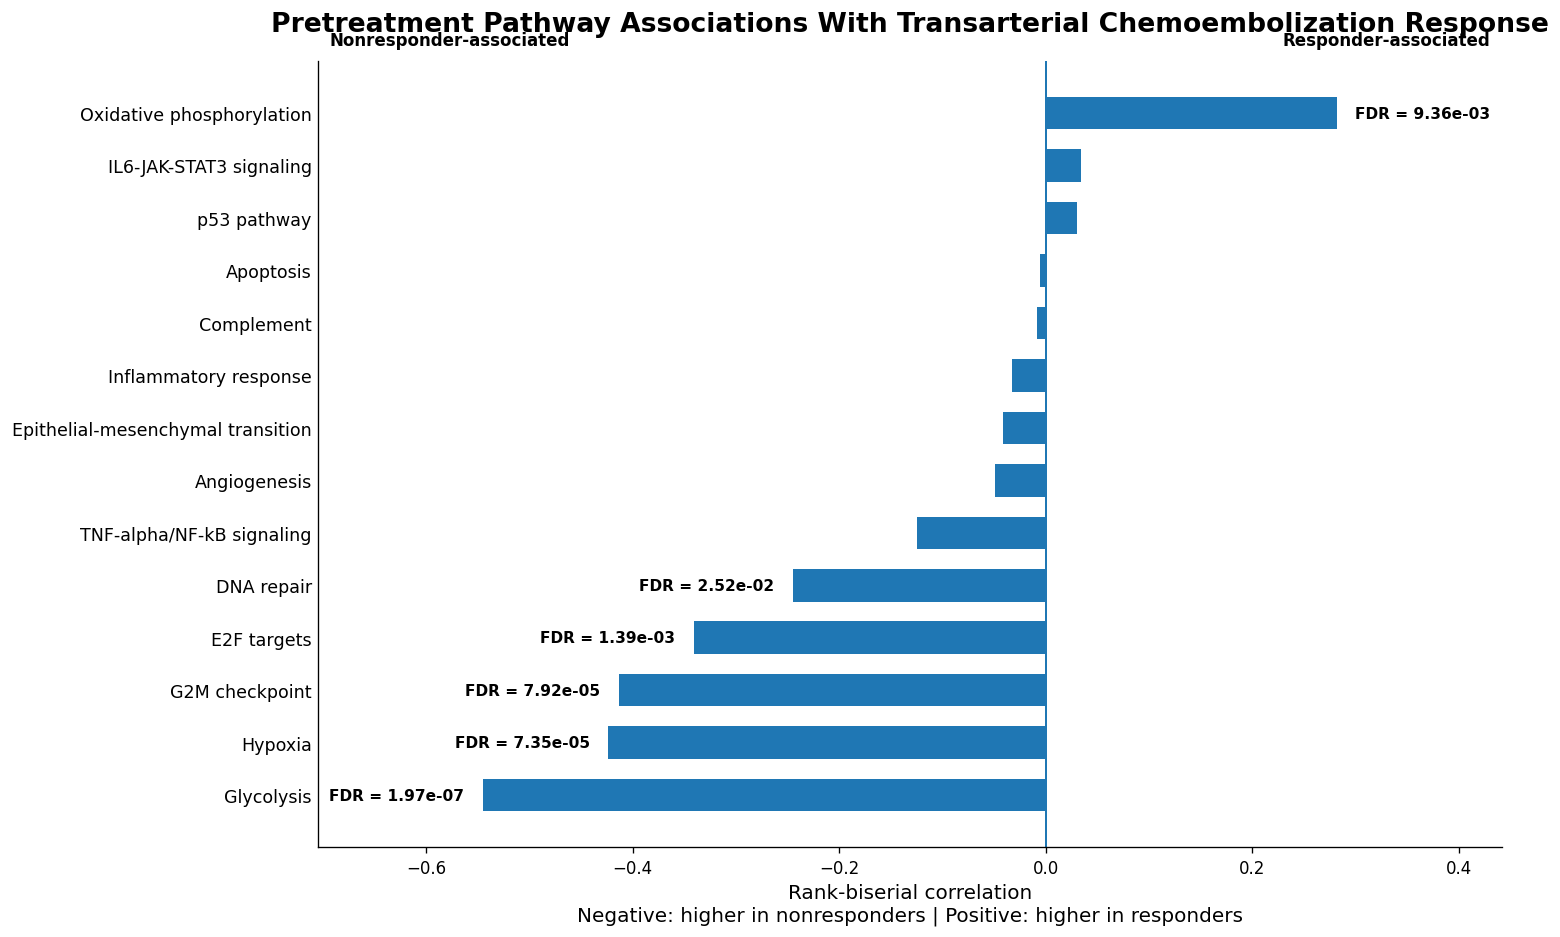


CELL 9 SUMMARY
FDR-significant pathways: 6/14

Strongest nonresponder-associated pathway:
  Glycolysis
  Rank-biserial correlation: -0.545
  FDR: 1.973e-07

Strongest responder-associated pathway:
  Oxidative phosphorylation
  Rank-biserial correlation: 0.282
  FDR: 9.356e-03

Files saved:
  /Users/rifaldyfajar/IGET2026_GSE104580/results/Pathway_Response_Associations.csv
  /Users/rifaldyfajar/IGET2026_GSE104580/figures/Figure_04_Pathway_Effect_Sizes.jpg
  /Users/rifaldyfajar/IGET2026_GSE104580/figures/Figure_04_Pathway_Effect_Sizes.png

✓ CELL 9 COMPLETED SUCCESSFULLY.


In [23]:
# CELL 9 — PATHWAY ASSOCIATIONS WITH TACE RESPONSE
# Complete fixed version with publication-quality figure

from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

# ============================================================
# 9A. PREPARE RESPONSE GROUPS
# ============================================================

y = metadata["response_binary"].astype(int).copy()

response_mask = y == 1
nonresponse_mask = y == 0

assert pathway_scores.index.equals(metadata.index), (
    "Pathway-score samples are not aligned with metadata."
)

assert int(response_mask.sum()) == 81, (
    f"Expected 81 responders, found {int(response_mask.sum())}."
)

assert int(nonresponse_mask.sum()) == 66, (
    f"Expected 66 nonresponders, found {int(nonresponse_mask.sum())}."
)

print("PATHWAY ASSOCIATION ANALYSIS")
print("=" * 50)
print("Responders:", int(response_mask.sum()))
print("Nonresponders:", int(nonresponse_mask.sum()))
print("Pathways tested:", pathway_scores.shape[1])


# ============================================================
# 9B. MANN–WHITNEY U TEST AND EFFECT SIZE
# ============================================================

association_rows = []

for pathway in pathway_scores.columns:

    responder_values = (
        pathway_scores.loc[response_mask, pathway]
        .dropna()
        .astype(float)
    )

    nonresponder_values = (
        pathway_scores.loc[nonresponse_mask, pathway]
        .dropna()
        .astype(float)
    )

    u_statistic, p_value = mannwhitneyu(
        responder_values,
        nonresponder_values,
        alternative="two-sided",
        method="auto"
    )

    n_responder = len(responder_values)
    n_nonresponder = len(nonresponder_values)

    # Rank-biserial correlation derived from the Mann–Whitney U statistic.
    #
    # Positive:
    # pathway activity tends to be higher in responders.
    #
    # Negative:
    # pathway activity tends to be higher in nonresponders.
    rank_biserial = (
        (2.0 * u_statistic)
        / (n_responder * n_nonresponder)
        - 1.0
    )

    association_rows.append({
        "pathway": pathway,
        "n_responder": n_responder,
        "n_nonresponder": n_nonresponder,
        "median_responder": float(responder_values.median()),
        "median_nonresponder": float(nonresponder_values.median()),
        "median_difference_response_minus_nonresponse": float(
            responder_values.median()
            - nonresponder_values.median()
        ),
        "rank_biserial_correlation": float(rank_biserial),
        "mann_whitney_u": float(u_statistic),
        "p_value": float(p_value)
    })


pathway_association = pd.DataFrame(association_rows)

pathway_association["fdr"] = multipletests(
    pathway_association["p_value"],
    method="fdr_bh"
)[1]

pathway_association["significant_fdr_0.05"] = (
    pathway_association["fdr"] < 0.05
)

pathway_association["direction"] = np.where(
    pathway_association["rank_biserial_correlation"] > 0,
    "Higher in responders",
    np.where(
        pathway_association["rank_biserial_correlation"] < 0,
        "Higher in nonresponders",
        "No direction"
    )
)

# Sort from strongest nonresponse-associated pathway
# to strongest response-associated pathway.
pathway_association = (
    pathway_association
    .sort_values(
        "rank_biserial_correlation",
        ascending=True
    )
    .reset_index(drop=True)
)

pathway_association.to_csv(
    RESULTS_DIR / "Pathway_Response_Associations.csv",
    index=False
)

print("\nPATHWAY ASSOCIATION RESULTS")
print("=" * 50)

display(
    pathway_association[
        [
            "pathway",
            "median_responder",
            "median_nonresponder",
            "median_difference_response_minus_nonresponse",
            "rank_biserial_correlation",
            "p_value",
            "fdr",
            "direction"
        ]
    ]
)


# ============================================================
# 9C. PUBLICATION-QUALITY EFFECT-SIZE FIGURE
# ============================================================

plot_df = pathway_association.copy()

n_pathways = len(plot_df)

fig_height = max(
    7.5,
    0.55 * n_pathways
)

fig, ax = plt.subplots(
    figsize=(12.5, fig_height)
)

y_positions = np.arange(n_pathways)

bars = ax.barh(
    y_positions,
    plot_df["rank_biserial_correlation"],
    height=0.62,
    edgecolor="none"
)

ax.axvline(
    x=0,
    linewidth=1.2
)

ax.set_yticks(y_positions)

ax.set_yticklabels(
    plot_df["pathway"],
    fontsize=10.5
)

ax.set_xlabel(
    "Rank-biserial correlation\n"
    "Negative: higher in nonresponders | "
    "Positive: higher in responders",
    fontsize=12
)

ax.set_ylabel("")

ax.set_title(
    "Pretreatment Pathway Associations With "
    "Transarterial Chemoembolization Response",
    fontsize=16,
    fontweight="bold",
    pad=18
)

# Give enough room for labels on both sides.
minimum_x = min(
    -0.65,
    plot_df["rank_biserial_correlation"].min() - 0.16
)

maximum_x = max(
    0.42,
    plot_df["rank_biserial_correlation"].max() + 0.16
)

ax.set_xlim(
    minimum_x,
    maximum_x
)

# Annotate only FDR-significant pathways.
# This keeps the figure readable and prevents label overlap.
for row_number, row in plot_df.iterrows():

    if row["fdr"] >= 0.05:
        continue

    effect = row["rank_biserial_correlation"]

    if effect < 0:
        text_x = effect - 0.018
        horizontal_alignment = "right"
    else:
        text_x = effect + 0.018
        horizontal_alignment = "left"

    ax.text(
        text_x,
        row_number,
        f"FDR = {row['fdr']:.2e}",
        va="center",
        ha=horizontal_alignment,
        fontsize=9.2,
        fontweight="bold"
    )

# Add subtle labels to explain each direction.
ax.text(
    0.01,
    1.015,
    "Responder-associated",
    transform=ax.transAxes,
    ha="left",
    va="bottom",
    fontsize=10,
    fontweight="bold"
)

ax.text(
    0.99,
    1.015,
    "Nonresponder-associated",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=10,
    fontweight="bold"
)

# The above text positions correspond to visual sides only if
# negative values are left and positive values are right.
# Correct the wording to match the actual axis.
ax.texts[-2].set_text("Nonresponder-associated")
ax.texts[-1].set_text("Responder-associated")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(
    axis="x",
    labelsize=10
)

ax.tick_params(
    axis="y",
    length=0
)

fig.subplots_adjust(
    left=0.32,
    right=0.97,
    top=0.88,
    bottom=0.15
)

figure_path_jpg = (
    FIGURES_DIR
    / "Figure_04_Pathway_Effect_Sizes.jpg"
)

figure_path_png = (
    FIGURES_DIR
    / "Figure_04_Pathway_Effect_Sizes.png"
)

fig.savefig(
    figure_path_jpg,
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    figure_path_png,
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 9D. AUTOMATIC RESULT SUMMARY
# ============================================================

significant_pathways = (
    pathway_association[
        pathway_association["fdr"] < 0.05
    ]
    .copy()
)

n_significant = len(significant_pathways)

strongest_nonresponse_pathway = (
    pathway_association
    .sort_values(
        "rank_biserial_correlation",
        ascending=True
    )
    .iloc[0]
)

strongest_response_pathway = (
    pathway_association
    .sort_values(
        "rank_biserial_correlation",
        ascending=False
    )
    .iloc[0]
)

print("\nCELL 9 SUMMARY")
print("=" * 50)

print(
    "FDR-significant pathways:",
    f"{n_significant}/{len(pathway_association)}"
)

print(
    "\nStrongest nonresponder-associated pathway:"
)

print(
    f"  {strongest_nonresponse_pathway['pathway']}"
)

print(
    "  Rank-biserial correlation:",
    f"{strongest_nonresponse_pathway['rank_biserial_correlation']:.3f}"
)

print(
    "  FDR:",
    f"{strongest_nonresponse_pathway['fdr']:.3e}"
)

print(
    "\nStrongest responder-associated pathway:"
)

print(
    f"  {strongest_response_pathway['pathway']}"
)

print(
    "  Rank-biserial correlation:",
    f"{strongest_response_pathway['rank_biserial_correlation']:.3f}"
)

print(
    "  FDR:",
    f"{strongest_response_pathway['fdr']:.3e}"
)

print("\nFiles saved:")
print(" ", RESULTS_DIR / "Pathway_Response_Associations.csv")
print(" ", figure_path_jpg)
print(" ", figure_path_png)

print("\n✓ CELL 9 COMPLETED SUCCESSFULLY.")

Selected number of endotypes: 2


,k,silhouette_score,mean_subsampling_ARI,median_subsampling_ARI,ARI_025,ARI_975
0,2,0.281596,0.883347,0.932211,0.574997,1.0
1,3,0.266532,0.834306,0.841534,0.499112,1.0
2,4,0.240997,0.769530,0.824295,0.389745,1.0
3,5,0.216006,0.854629,0.885535,0.578379,1.0


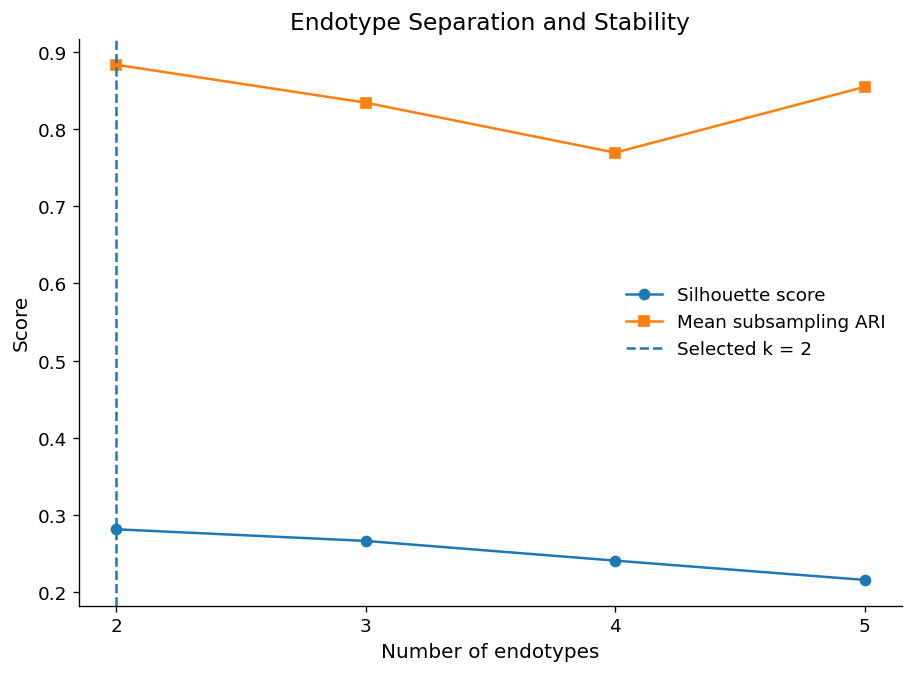

In [25]:
# CELL 10 — ENDOTYPE NUMBER SELECTION

X_pathway = pathway_scores.copy()

# Standardization is required because pathways may have different scales.
X_endotype = pd.DataFrame(
    StandardScaler().fit_transform(X_pathway),
    index=X_pathway.index,
    columns=X_pathway.columns
)

candidate_k = range(2, 6)
n_subsamples = 150
subsample_fraction = 0.80

endotype_selection_rows = []

for k in candidate_k:
    full_model = KMeans(
        n_clusters=k,
        n_init=100,
        random_state=RANDOM_STATE
    )

    full_labels = full_model.fit_predict(X_endotype)
    silhouette = silhouette_score(X_endotype, full_labels)

    stability_scores = []
    rng = np.random.default_rng(RANDOM_STATE + k)

    n_subsample = int(np.floor(len(X_endotype) * subsample_fraction))

    for repetition in range(n_subsamples):
        selected_positions = rng.choice(
            len(X_endotype),
            size=n_subsample,
            replace=False
        )

        X_sub = X_endotype.iloc[selected_positions]

        sub_model = KMeans(
            n_clusters=k,
            n_init=25,
            random_state=RANDOM_STATE + repetition
        )

        sub_labels = sub_model.fit_predict(X_sub)
        reference_labels = full_labels[selected_positions]

        stability_scores.append(
            adjusted_rand_score(reference_labels, sub_labels)
        )

    endotype_selection_rows.append({
        "k": k,
        "silhouette_score": silhouette,
        "mean_subsampling_ARI": np.mean(stability_scores),
        "median_subsampling_ARI": np.median(stability_scores),
        "ARI_025": np.quantile(stability_scores, 0.025),
        "ARI_975": np.quantile(stability_scores, 0.975)
    })

endotype_selection = pd.DataFrame(endotype_selection_rows)

# Prefer a stable model. Among stable candidates, maximize silhouette.
stable_candidates = endotype_selection[
    endotype_selection["mean_subsampling_ARI"] >= 0.60
]

if not stable_candidates.empty:
    selected_k = int(
        stable_candidates.sort_values(
            ["silhouette_score", "mean_subsampling_ARI"],
            ascending=False
        ).iloc[0]["k"]
    )
else:
    # Transparent fallback if no solution reaches ARI 0.60.
    endotype_selection["combined_score"] = (
        endotype_selection["silhouette_score"]
        + 0.25 * endotype_selection["mean_subsampling_ARI"]
    )

    selected_k = int(
        endotype_selection.sort_values(
            "combined_score",
            ascending=False
        ).iloc[0]["k"]
    )

print("Selected number of endotypes:", selected_k)
display(endotype_selection)

endotype_selection.to_csv(
    RESULTS_DIR / "Endotype_Number_Selection.csv",
    index=False
)

fig, ax = plt.subplots(figsize=(7.5, 5.5))

ax.plot(
    endotype_selection["k"],
    endotype_selection["silhouette_score"],
    marker="o",
    label="Silhouette score"
)

ax.plot(
    endotype_selection["k"],
    endotype_selection["mean_subsampling_ARI"],
    marker="s",
    label="Mean subsampling ARI"
)

ax.axvline(
    selected_k,
    linestyle="--",
    label=f"Selected k = {selected_k}"
)

ax.set_xlabel("Number of endotypes")
ax.set_ylabel("Score")
ax.set_title("Endotype Separation and Stability")
ax.set_xticks(list(candidate_k))
ax.legend(frameon=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.savefig(
    FIGURES_DIR / "Figure_05_Endotype_Selection.jpg",
    bbox_inches="tight"
)
plt.show()

Endotype names:
1 -> E1: TNF-alpha/NF-kB signaling / Apoptosis
2 -> E2: Oxidative phosphorylation / DNA repair

Endotype-response chi-square P = 0.146325


response,Nonresponder,Responder
endotype,,
E1: TNF-alpha/NF-kB signaling / Apoptosis,39,37
E2: Oxidative phosphorylation / DNA repair,27,44


,n,responders,response_rate,nonresponders
endotype,,,,
E1: TNF-alpha/NF-kB signaling / Apoptosis,76,37,0.486842,39
E2: Oxidative phosphorylation / DNA repair,71,44,0.619718,27


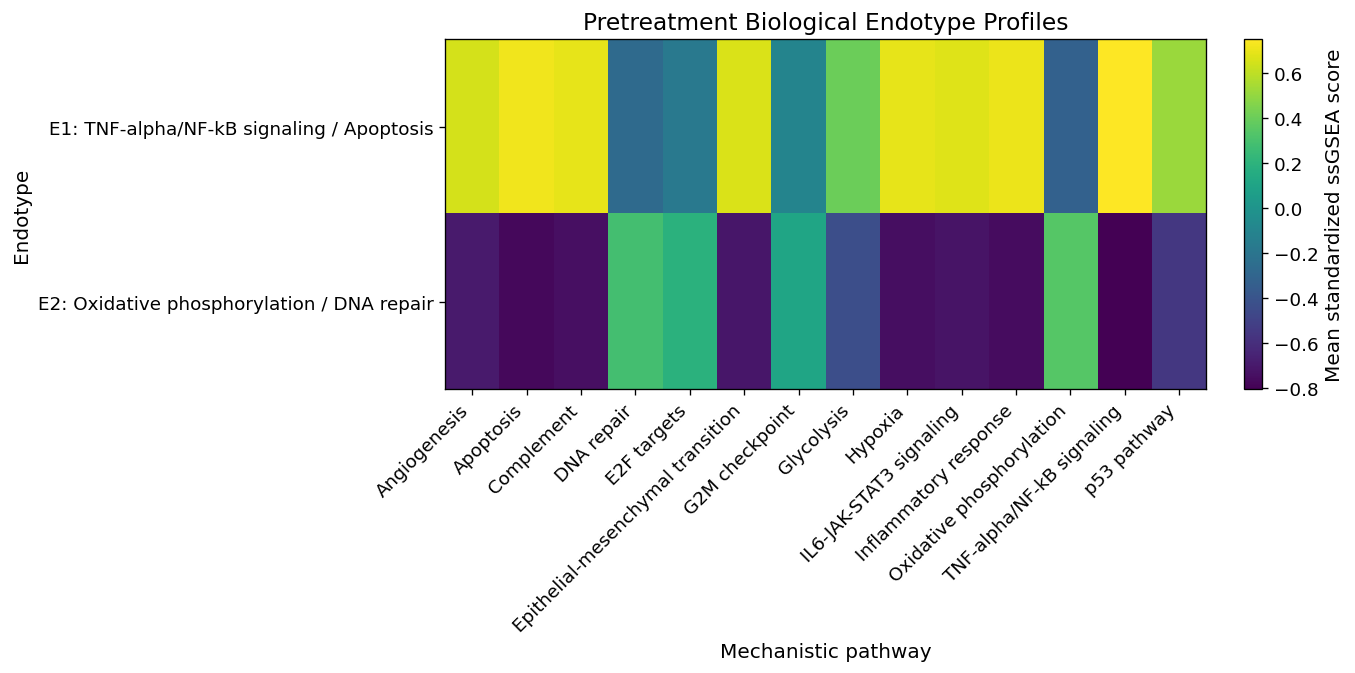

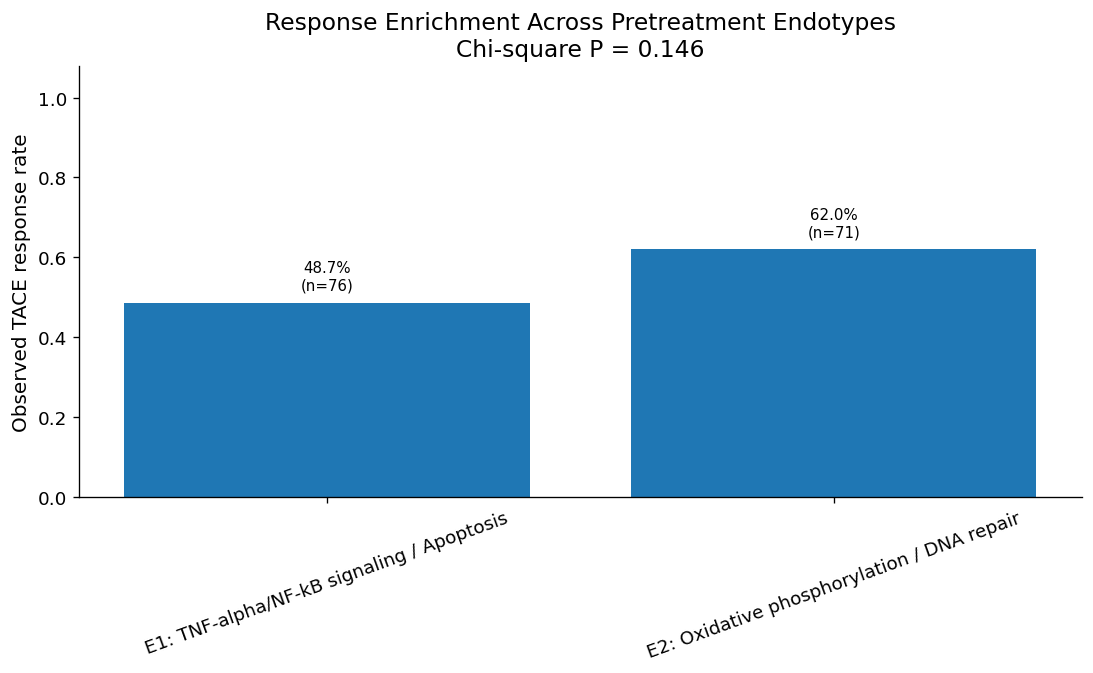

In [27]:
# CELL 11 — FINAL ENDOTYPE MODEL

final_endotype_model = KMeans(
    n_clusters=selected_k,
    n_init=250,
    random_state=RANDOM_STATE
)

endotype_numeric = final_endotype_model.fit_predict(X_endotype) + 1

endotype_df = metadata[["response", "response_binary"]].copy()
endotype_df["endotype_number"] = endotype_numeric

# Calculate standardized pathway profiles for each endotype.
endotype_profile = (
    X_endotype
    .assign(endotype=endotype_numeric)
    .groupby("endotype")
    .mean()
)

# Give each endotype an objective descriptive name using its two
# most elevated pathways relative to the full cohort.
endotype_name_map = {}

for cluster_number in endotype_profile.index:
    top_pathways = (
        endotype_profile.loc[cluster_number]
        .sort_values(ascending=False)
        .head(2)
        .index
        .tolist()
    )

    endotype_name_map[cluster_number] = (
        f"E{cluster_number}: "
        + " / ".join(top_pathways)
    )

endotype_df["endotype"] = endotype_df["endotype_number"].map(
    endotype_name_map
)

endotype_df.to_csv(
    RESULTS_DIR / "Patient_Endotype_Assignments.csv"
)

endotype_profile.index = [
    endotype_name_map[index]
    for index in endotype_profile.index
]

endotype_profile.to_csv(
    RESULTS_DIR / "Endotype_Pathway_Profiles.csv"
)

print("Endotype names:")
for number, name in endotype_name_map.items():
    print(number, "->", name)

# Response enrichment table.
contingency = pd.crosstab(
    endotype_df["endotype"],
    endotype_df["response"]
)

chi2, chi2_p, chi2_dof, expected = chi2_contingency(contingency)

endotype_response_summary = (
    endotype_df
    .groupby("endotype")
    .agg(
        n=("response_binary", "size"),
        responders=("response_binary", "sum"),
        response_rate=("response_binary", "mean")
    )
    .sort_values("response_rate")
)

endotype_response_summary["nonresponders"] = (
    endotype_response_summary["n"]
    - endotype_response_summary["responders"]
)

endotype_response_summary.to_csv(
    RESULTS_DIR / "Endotype_Response_Summary.csv"
)

print(f"\nEndotype-response chi-square P = {chi2_p:.6g}")
display(contingency)
display(endotype_response_summary)

# Endotype pathway heatmap.
profile_plot = endotype_profile.copy()

fig, ax = plt.subplots(
    figsize=(max(10, 0.8 * profile_plot.shape[1]), 5.5)
)

image = ax.imshow(
    profile_plot.values,
    aspect="auto"
)

ax.set_xticks(np.arange(profile_plot.shape[1]))
ax.set_xticklabels(
    profile_plot.columns,
    rotation=45,
    ha="right"
)

ax.set_yticks(np.arange(profile_plot.shape[0]))
ax.set_yticklabels(profile_plot.index)

ax.set_title("Pretreatment Biological Endotype Profiles")
ax.set_xlabel("Mechanistic pathway")
ax.set_ylabel("Endotype")

colorbar = fig.colorbar(image, ax=ax)
colorbar.set_label("Mean standardized ssGSEA score")

fig.savefig(
    FIGURES_DIR / "Figure_06_Endotype_Pathway_Heatmap.jpg",
    bbox_inches="tight"
)
plt.show()


# Response-rate plot.
fig, ax = plt.subplots(figsize=(9, 5.5))

summary_plot = endotype_response_summary.sort_values(
    "response_rate"
)

bars = ax.bar(
    summary_plot.index,
    summary_plot["response_rate"]
)

for bar, (_, row) in zip(bars, summary_plot.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        row["response_rate"] + 0.025,
        f"{row['response_rate']:.1%}\n(n={int(row['n'])})",
        ha="center",
        va="bottom",
        fontsize=9
    )

ax.set_ylim(0, 1.08)
ax.set_ylabel("Observed TACE response rate")
ax.set_title(
    f"Response Enrichment Across Pretreatment Endotypes\n"
    f"Chi-square P = {chi2_p:.3g}"
)
ax.tick_params(axis="x", rotation=20)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.savefig(
    FIGURES_DIR / "Figure_07_Endotype_Response_Rates.jpg",
    bbox_inches="tight"
)
plt.show()

In [29]:
# CELL 12 — NESTED REPEATED CROSS-VALIDATED MACHINE LEARNING

X = pathway_scores.copy()
y = metadata["response_binary"].astype(int).copy()

# Primary model:
# Elastic-net logistic regression is selected for interpretability,
# regularization, and suitability for a small-to-moderate clinical cohort.
model_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        penalty="elasticnet",
        solver="saga",
        max_iter=20000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

parameter_grid = {
    "model__C": np.logspace(-2, 2, 9),
    "model__l1_ratio": [0.00, 0.25, 0.50, 0.75, 1.00]
}

outer_cv = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=10,
    random_state=RANDOM_STATE
)

# Store predictions from every repeated outer fold.
prediction_records = []
fold_performance = []
selected_hyperparameters = []

for fold_number, (train_indices, test_indices) in enumerate(
    outer_cv.split(X, y),
    start=1
):
    X_train = X.iloc[train_indices]
    X_test = X.iloc[test_indices]

    y_train = y.iloc[train_indices]
    y_test = y.iloc[test_indices]

    inner_cv = StratifiedKFold(
        n_splits=4,
        shuffle=True,
        random_state=RANDOM_STATE + fold_number
    )

    search = GridSearchCV(
        estimator=model_pipeline,
        param_grid=parameter_grid,
        scoring="roc_auc",
        cv=inner_cv,
        n_jobs=-1,
        refit=True,
        error_score="raise"
    )

    search.fit(X_train, y_train)

    probabilities = search.predict_proba(X_test)[:, 1]

    fold_auc = roc_auc_score(y_test, probabilities)
    fold_ap = average_precision_score(y_test, probabilities)
    fold_brier = brier_score_loss(y_test, probabilities)

    fold_performance.append({
        "outer_fold": fold_number,
        "n_train": len(train_indices),
        "n_test": len(test_indices),
        "roc_auc": fold_auc,
        "average_precision": fold_ap,
        "brier_score": fold_brier
    })

    selected_hyperparameters.append({
        "outer_fold": fold_number,
        "best_C": search.best_params_["model__C"],
        "best_l1_ratio": search.best_params_["model__l1_ratio"],
        "inner_best_auc": search.best_score_
    })

    for sample_position, probability in zip(
        test_indices,
        probabilities
    ):
        prediction_records.append({
            "sample_id": X.index[sample_position],
            "observed_response": int(y.iloc[sample_position]),
            "predicted_probability": float(probability),
            "outer_fold": fold_number
        })

    if fold_number % 10 == 0:
        print(f"Completed outer fold {fold_number}/50")

prediction_records = pd.DataFrame(prediction_records)
fold_performance = pd.DataFrame(fold_performance)
selected_hyperparameters = pd.DataFrame(selected_hyperparameters)

# Every sample receives predictions in each of the 10 outer repetitions.
oof_predictions = (
    prediction_records
    .groupby("sample_id")
    .agg(
        observed_response=("observed_response", "first"),
        predicted_probability=("predicted_probability", "mean"),
        prediction_sd=("predicted_probability", "std"),
        number_of_predictions=("predicted_probability", "size")
    )
    .reindex(X.index)
)

assert oof_predictions["number_of_predictions"].min() == 10
assert oof_predictions["number_of_predictions"].max() == 10

prediction_records.to_csv(
    RESULTS_DIR / "All_Repeated_Outer_Fold_Predictions.csv",
    index=False
)

fold_performance.to_csv(
    RESULTS_DIR / "Outer_Fold_Performance.csv",
    index=False
)

selected_hyperparameters.to_csv(
    RESULTS_DIR / "Nested_CV_Selected_Hyperparameters.csv",
    index=False
)

oof_predictions.to_csv(
    RESULTS_DIR / "Patient_Level_Repeated_OOF_Predictions.csv"
)

print("\nNested cross-validation completed.")
display(fold_performance.describe())
display(oof_predictions.head())

Completed outer fold 10/50
Completed outer fold 20/50
Completed outer fold 30/50
Completed outer fold 40/50
Completed outer fold 50/50

Nested cross-validation completed.


,outer_fold,n_train,n_test,roc_auc,average_precision,brier_score
count,50.00000,50.000000,50.000000,50.000000,50.000000,50.000000
mean,25.50000,117.600000,29.400000,0.785885,0.805883,0.193875
std,14.57738,0.494872,0.494872,0.080821,0.085298,0.034646
min,1.00000,117.000000,29.000000,0.615385,0.593674,0.116599
25%,13.25000,117.000000,29.000000,0.740385,0.763889,0.169401
50%,25.50000,118.000000,29.000000,0.790865,0.813341,0.193069
75%,37.75000,118.000000,30.000000,0.831387,0.868558,0.213571
max,50.00000,118.000000,30.000000,0.977679,0.981536,0.291415


,observed_response,predicted_probability,prediction_sd,number_of_predictions
name,,,,
GSM2803655,1,0.699012,0.074520,10
GSM2803656,1,0.560696,0.052404,10
GSM2803657,1,0.818832,0.059433,10
GSM2803658,1,0.670148,0.156717,10
GSM2803659,1,0.675246,0.058964,10


In [31]:
# CELL 13 — MODEL PERFORMANCE AND UNCERTAINTY

observed = oof_predictions["observed_response"].astype(int).values
predicted = oof_predictions["predicted_probability"].values

def bootstrap_metric_ci(
    y_true,
    y_probability,
    metric_function,
    n_bootstrap=3000,
    random_state=42
):
    """Patient-level nonparametric bootstrap confidence interval."""
    rng = np.random.default_rng(random_state)
    estimates = []
    n = len(y_true)

    for _ in range(n_bootstrap):
        indices = rng.choice(n, size=n, replace=True)

        # ROC-based metrics require both classes.
        if len(np.unique(y_true[indices])) < 2:
            continue

        try:
            estimate = metric_function(
                y_true[indices],
                y_probability[indices]
            )
            estimates.append(estimate)
        except Exception:
            continue

    return (
        float(np.quantile(estimates, 0.025)),
        float(np.quantile(estimates, 0.975))
    )


roc_auc = roc_auc_score(observed, predicted)
roc_ci = bootstrap_metric_ci(
    observed,
    predicted,
    roc_auc_score
)

average_precision = average_precision_score(observed, predicted)
ap_ci = bootstrap_metric_ci(
    observed,
    predicted,
    average_precision_score
)

brier = brier_score_loss(observed, predicted)

# Threshold-independent primary reporting uses AUROC and AUPRC.
# For descriptive classification statistics, use threshold 0.50.
fixed_threshold = 0.50
predicted_class = (predicted >= fixed_threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(
    observed,
    predicted_class
).ravel()

sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)
balanced_accuracy = balanced_accuracy_score(
    observed,
    predicted_class
)

# Calibration intercept and slope.
epsilon = 1e-6
clipped_probability = np.clip(
    predicted,
    epsilon,
    1 - epsilon
)

logit_probability = np.log(
    clipped_probability / (1 - clipped_probability)
)

calibration_design = sm.add_constant(logit_probability)

try:
    calibration_model = sm.Logit(
        observed,
        calibration_design
    ).fit(disp=False)

    calibration_intercept = float(calibration_model.params[0])
    calibration_slope = float(calibration_model.params[1])

except Exception as error:
    calibration_intercept = np.nan
    calibration_slope = np.nan
    print("Calibration regression warning:", error)

performance_summary = pd.DataFrame([{
    "n_samples": len(observed),
    "n_responders": int(observed.sum()),
    "n_nonresponders": int(len(observed) - observed.sum()),
    "nested_repeated_cv_roc_auc": roc_auc,
    "roc_auc_ci_lower": roc_ci[0],
    "roc_auc_ci_upper": roc_ci[1],
    "nested_repeated_cv_average_precision": average_precision,
    "average_precision_ci_lower": ap_ci[0],
    "average_precision_ci_upper": ap_ci[1],
    "response_prevalence": observed.mean(),
    "brier_score": brier,
    "calibration_intercept": calibration_intercept,
    "calibration_slope": calibration_slope,
    "classification_threshold": fixed_threshold,
    "sensitivity_at_0.50": sensitivity,
    "specificity_at_0.50": specificity,
    "balanced_accuracy_at_0.50": balanced_accuracy
}])

performance_summary.to_csv(
    RESULTS_DIR / "Primary_Model_Performance.csv",
    index=False
)

display(performance_summary.T)

print(
    f"Nested repeated-CV AUROC: "
    f"{roc_auc:.3f} "
    f"(95% CI {roc_ci[0]:.3f}–{roc_ci[1]:.3f})"
)

print(
    f"Nested repeated-CV AUPRC: "
    f"{average_precision:.3f} "
    f"(95% CI {ap_ci[0]:.3f}–{ap_ci[1]:.3f})"
)

print(f"Brier score: {brier:.3f}")
print(f"Calibration intercept: {calibration_intercept:.3f}")
print(f"Calibration slope: {calibration_slope:.3f}")

,0
n_samples,147.000000
n_responders,81.000000
n_nonresponders,66.000000
nested_repeated_cv_roc_auc,0.783577
roc_auc_ci_lower,0.705928
roc_auc_ci_upper,0.856165
nested_repeated_cv_average_precision,0.787771
average_precision_ci_lower,0.692569
average_precision_ci_upper,0.878179
response_prevalence,0.551020


Nested repeated-CV AUROC: 0.784 (95% CI 0.706–0.856)
Nested repeated-CV AUPRC: 0.788 (95% CI 0.693–0.878)
Brier score: 0.187
Calibration intercept: 0.195
Calibration slope: 1.109


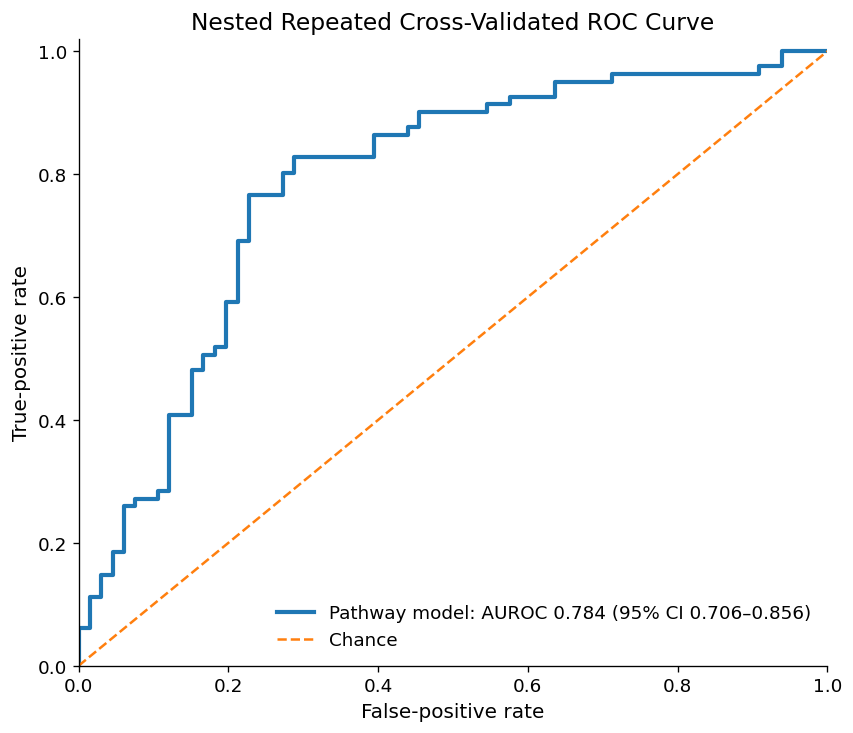

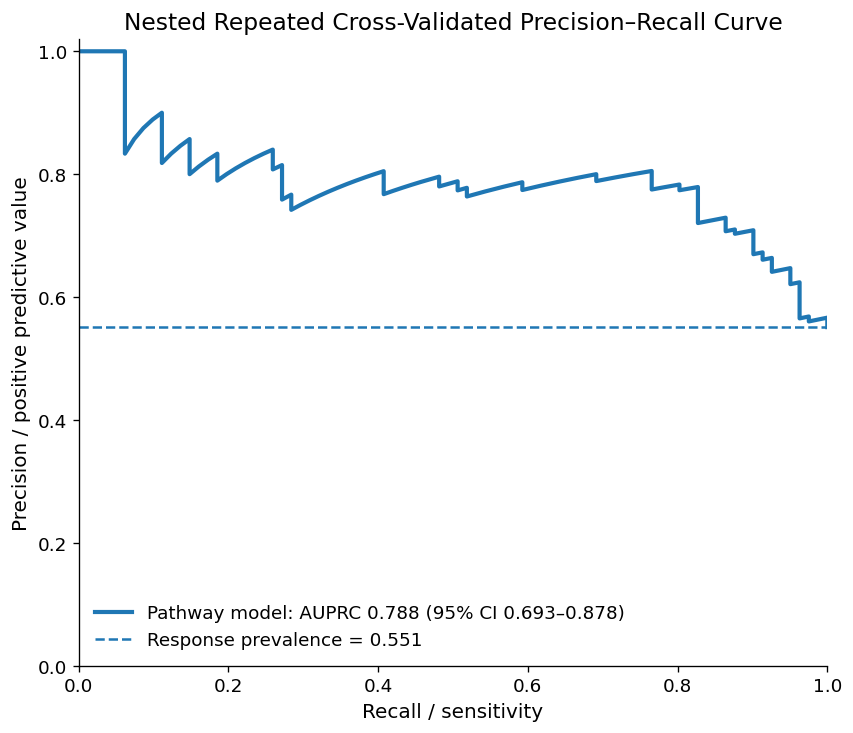

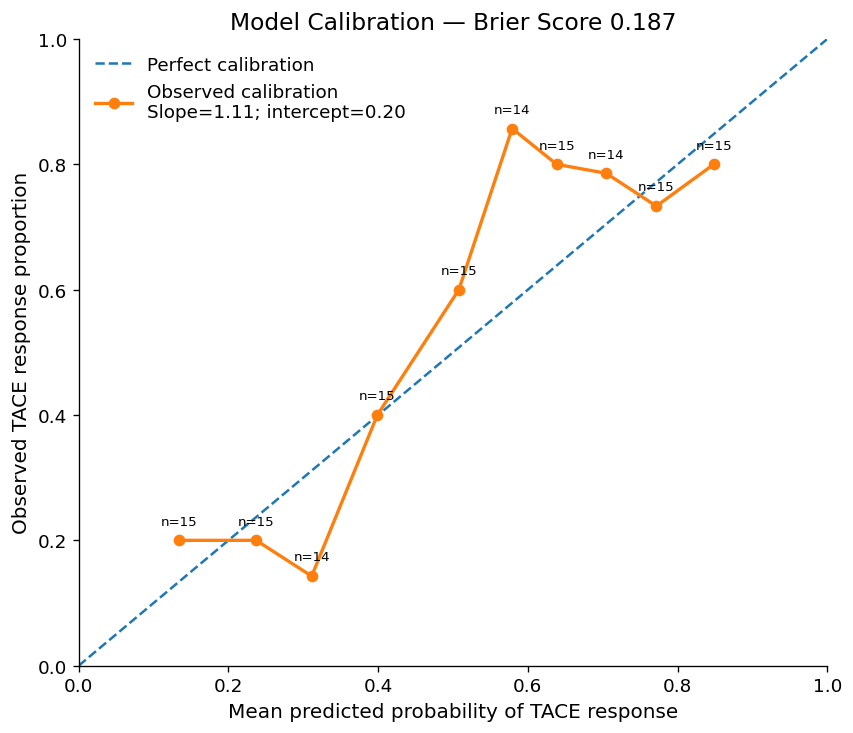

In [33]:
# CELL 14 — MODEL PERFORMANCE FIGURES

# 14A. ROC curve
fpr, tpr, roc_thresholds = roc_curve(observed, predicted)

fig, ax = plt.subplots(figsize=(7, 6))

ax.plot(
    fpr,
    tpr,
    linewidth=2.5,
    label=(
        f"Pathway model: AUROC {roc_auc:.3f} "
        f"(95% CI {roc_ci[0]:.3f}–{roc_ci[1]:.3f})"
    )
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Chance"
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.set_xlabel("False-positive rate")
ax.set_ylabel("True-positive rate")
ax.set_title("Nested Repeated Cross-Validated ROC Curve")
ax.legend(frameon=False, loc="lower right")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.savefig(
    FIGURES_DIR / "Figure_08_Nested_CV_ROC.jpg",
    bbox_inches="tight"
)
plt.show()


# 14B. Precision-recall curve
precision, recall, pr_thresholds = precision_recall_curve(
    observed,
    predicted
)

prevalence = observed.mean()

fig, ax = plt.subplots(figsize=(7, 6))

ax.plot(
    recall,
    precision,
    linewidth=2.5,
    label=(
        f"Pathway model: AUPRC {average_precision:.3f} "
        f"(95% CI {ap_ci[0]:.3f}–{ap_ci[1]:.3f})"
    )
)

ax.axhline(
    prevalence,
    linestyle="--",
    label=f"Response prevalence = {prevalence:.3f}"
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.set_xlabel("Recall / sensitivity")
ax.set_ylabel("Precision / positive predictive value")
ax.set_title("Nested Repeated Cross-Validated Precision–Recall Curve")
ax.legend(frameon=False, loc="lower left")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.savefig(
    FIGURES_DIR / "Figure_09_Nested_CV_Precision_Recall.jpg",
    bbox_inches="tight"
)
plt.show()


# 14C. Calibration plot using equal-frequency bins.
calibration_data = pd.DataFrame({
    "observed": observed,
    "predicted": predicted
})

calibration_data["bin"] = pd.qcut(
    calibration_data["predicted"],
    q=10,
    duplicates="drop"
)

calibration_points = (
    calibration_data
    .groupby("bin", observed=True)
    .agg(
        mean_predicted=("predicted", "mean"),
        observed_response_rate=("observed", "mean"),
        n=("observed", "size")
    )
    .reset_index(drop=True)
)

fig, ax = plt.subplots(figsize=(7, 6))

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

ax.plot(
    calibration_points["mean_predicted"],
    calibration_points["observed_response_rate"],
    marker="o",
    linewidth=2,
    label=(
        f"Observed calibration\n"
        f"Slope={calibration_slope:.2f}; "
        f"intercept={calibration_intercept:.2f}"
    )
)

for _, row in calibration_points.iterrows():
    ax.text(
        row["mean_predicted"],
        row["observed_response_rate"] + 0.025,
        f"n={int(row['n'])}",
        ha="center",
        fontsize=8
    )

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel("Mean predicted probability of TACE response")
ax.set_ylabel("Observed TACE response proportion")
ax.set_title(f"Model Calibration — Brier Score {brier:.3f}")
ax.legend(frameon=False, loc="upper left")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.savefig(
    FIGURES_DIR / "Figure_10_Nested_CV_Calibration.jpg",
    bbox_inches="tight"
)
plt.show()

calibration_points.to_csv(
    RESULTS_DIR / "Calibration_Plot_Data.csv",
    index=False
)

Final hyperparameters:
{'model__C': 0.1, 'model__l1_ratio': 0.0}


,pathway,standardized_coefficient,bootstrap_median,bootstrap_ci_lower,bootstrap_ci_upper,nonzero_frequency,positive_frequency,negative_frequency,absolute_coefficient
0,Hypoxia,-0.553232,-0.547089,-0.780287,-0.317657,1.0,0.000,1.000,0.553232
1,Glycolysis,-0.507412,-0.508508,-0.758548,-0.266626,1.0,0.000,1.000,0.507412
2,DNA repair,-0.148552,-0.133193,-0.412957,0.110070,1.0,0.144,0.856,0.148552
3,G2M checkpoint,-0.138789,-0.147754,-0.337795,0.034828,1.0,0.052,0.948,0.138789
4,Complement,-0.084611,-0.074538,-0.285074,0.131163,1.0,0.224,0.776,0.084611
5,E2F targets,-0.060956,-0.070745,-0.259817,0.103413,1.0,0.207,0.793,0.060956
6,Inflammatory response,-0.036119,-0.038943,-0.188303,0.120122,1.0,0.330,0.670,0.036119
7,TNF-alpha/NF-kB signaling,-0.028267,-0.032187,-0.213351,0.156306,1.0,0.343,0.657,0.028267
8,Apoptosis,0.029523,0.036907,-0.150935,0.230269,1.0,0.627,0.373,0.029523
9,IL6-JAK-STAT3 signaling,0.081242,0.086191,-0.142757,0.296533,1.0,0.764,0.236,0.081242


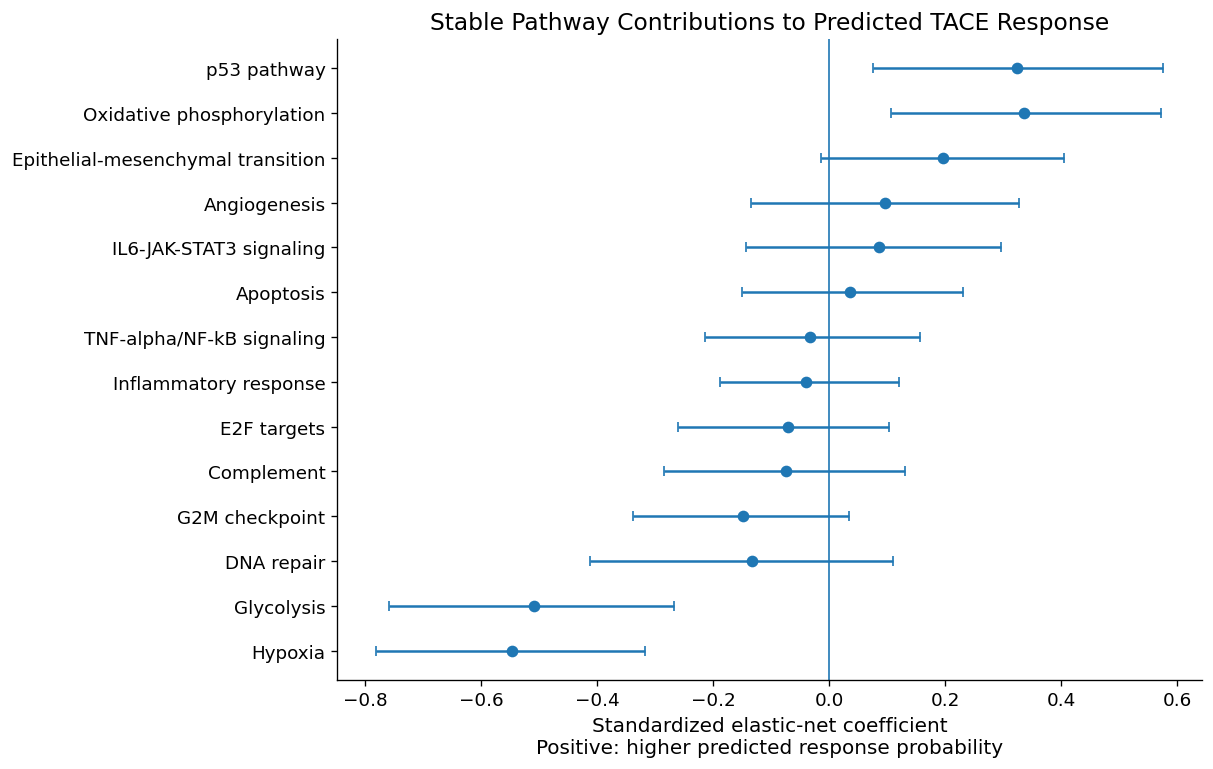

In [35]:
# CELL 15 — FINAL MODEL AND COEFFICIENT STABILITY

final_inner_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

final_search = GridSearchCV(
    estimator=model_pipeline,
    param_grid=parameter_grid,
    scoring="roc_auc",
    cv=final_inner_cv,
    n_jobs=-1,
    refit=True,
    error_score="raise"
)

final_search.fit(X, y)

final_model = final_search.best_estimator_

best_C = final_search.best_params_["model__C"]
best_l1_ratio = final_search.best_params_["model__l1_ratio"]

print("Final hyperparameters:")
print(final_search.best_params_)

joblib.dump(
    final_model,
    MODELS_DIR / "Final_Pathway_ElasticNet_Model.joblib"
)

with open(
    MODELS_DIR / "Final_Model_Features.json",
    "w"
) as file:
    json.dump(X.columns.tolist(), file, indent=2)

# Standardized model coefficients.
final_coefficients = final_model.named_steps["model"].coef_.ravel()

coefficient_df = pd.DataFrame({
    "pathway": X.columns,
    "standardized_coefficient": final_coefficients
})

# Bootstrap coefficient stability using fixed final hyperparameters.
fixed_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        penalty="elasticnet",
        solver="saga",
        C=best_C,
        l1_ratio=best_l1_ratio,
        max_iter=20000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

rng = np.random.default_rng(RANDOM_STATE)
n_bootstrap_coefficients = 1000
bootstrap_coefficients = []

for repetition in range(n_bootstrap_coefficients):
    # Stratified patient-level bootstrap.
    responder_indices = np.where(y.values == 1)[0]
    nonresponder_indices = np.where(y.values == 0)[0]

    sampled_responder = rng.choice(
        responder_indices,
        size=len(responder_indices),
        replace=True
    )

    sampled_nonresponder = rng.choice(
        nonresponder_indices,
        size=len(nonresponder_indices),
        replace=True
    )

    sampled_indices = np.concatenate([
        sampled_responder,
        sampled_nonresponder
    ])

    rng.shuffle(sampled_indices)

    bootstrap_model = clone(fixed_model)
    bootstrap_model.fit(
        X.iloc[sampled_indices],
        y.iloc[sampled_indices]
    )

    bootstrap_coefficients.append(
        bootstrap_model.named_steps["model"].coef_.ravel()
    )

bootstrap_coefficients = np.asarray(bootstrap_coefficients)

coefficient_df["bootstrap_median"] = np.median(
    bootstrap_coefficients,
    axis=0
)

coefficient_df["bootstrap_ci_lower"] = np.quantile(
    bootstrap_coefficients,
    0.025,
    axis=0
)

coefficient_df["bootstrap_ci_upper"] = np.quantile(
    bootstrap_coefficients,
    0.975,
    axis=0
)

coefficient_df["nonzero_frequency"] = (
    np.abs(bootstrap_coefficients) > 1e-8
).mean(axis=0)

coefficient_df["positive_frequency"] = (
    bootstrap_coefficients > 0
).mean(axis=0)

coefficient_df["negative_frequency"] = (
    bootstrap_coefficients < 0
).mean(axis=0)

coefficient_df["absolute_coefficient"] = (
    coefficient_df["standardized_coefficient"].abs()
)

coefficient_df = coefficient_df.sort_values(
    "standardized_coefficient"
).reset_index(drop=True)

coefficient_df.to_csv(
    RESULTS_DIR / "Final_Model_Pathway_Coefficients.csv",
    index=False
)

display(coefficient_df)

# Coefficient plot.
fig_height = max(6, 0.45 * len(coefficient_df))
fig, ax = plt.subplots(figsize=(10, fig_height))

plot_positions = np.arange(len(coefficient_df))

lower_error = (
    coefficient_df["bootstrap_median"]
    - coefficient_df["bootstrap_ci_lower"]
)

upper_error = (
    coefficient_df["bootstrap_ci_upper"]
    - coefficient_df["bootstrap_median"]
)

ax.errorbar(
    coefficient_df["bootstrap_median"],
    plot_positions,
    xerr=np.vstack([lower_error, upper_error]),
    fmt="o",
    capsize=3
)

ax.axvline(0, linewidth=1)
ax.set_yticks(plot_positions)
ax.set_yticklabels(coefficient_df["pathway"])
ax.set_xlabel(
    "Standardized elastic-net coefficient\n"
    "Positive: higher predicted response probability"
)
ax.set_title("Stable Pathway Contributions to Predicted TACE Response")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.savefig(
    FIGURES_DIR / "Figure_11_Pathway_Coefficient_Stability.jpg",
    bbox_inches="tight"
)
plt.show()

,observed_five_fold_cv_auc,mean_permuted_auc,sd_permuted_auc,permutation_p_value,n_permutations
0,0.799531,0.503335,0.06702,0.001996,500


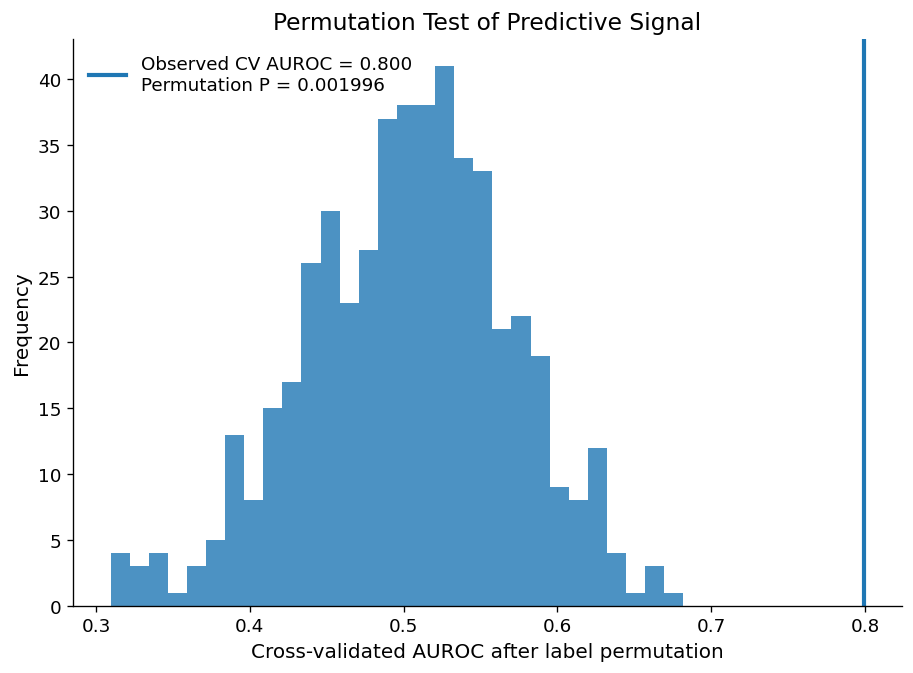

In [37]:
# CELL 16 — LABEL-PERMUTATION SIGNIFICANCE TEST

# A permutation test checks whether the pathway model performs
# better than would be expected after randomly reassigning response labels.

permutation_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

observed_cv_score, permutation_scores, permutation_p_value = (
    permutation_test_score(
        estimator=fixed_model,
        X=X,
        y=y,
        scoring="roc_auc",
        cv=permutation_cv,
        n_permutations=500,
        n_jobs=-1,
        random_state=RANDOM_STATE
    )
)

permutation_summary = pd.DataFrame([{
    "observed_five_fold_cv_auc": observed_cv_score,
    "mean_permuted_auc": permutation_scores.mean(),
    "sd_permuted_auc": permutation_scores.std(),
    "permutation_p_value": permutation_p_value,
    "n_permutations": len(permutation_scores)
}])

permutation_summary.to_csv(
    RESULTS_DIR / "Permutation_Test_Summary.csv",
    index=False
)

np.savetxt(
    RESULTS_DIR / "Permutation_AUC_Distribution.csv",
    permutation_scores,
    delimiter=","
)

display(permutation_summary)

fig, ax = plt.subplots(figsize=(7.5, 5.5))

ax.hist(
    permutation_scores,
    bins=30,
    alpha=0.8
)

ax.axvline(
    observed_cv_score,
    linewidth=2.5,
    label=(
        f"Observed CV AUROC = {observed_cv_score:.3f}\n"
        f"Permutation P = {permutation_p_value:.4g}"
    )
)

ax.set_xlabel("Cross-validated AUROC after label permutation")
ax.set_ylabel("Frequency")
ax.set_title("Permutation Test of Predictive Signal")
ax.legend(frameon=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.savefig(
    FIGURES_DIR / "Figure_12_Permutation_Test.jpg",
    bbox_inches="tight"
)
plt.show()

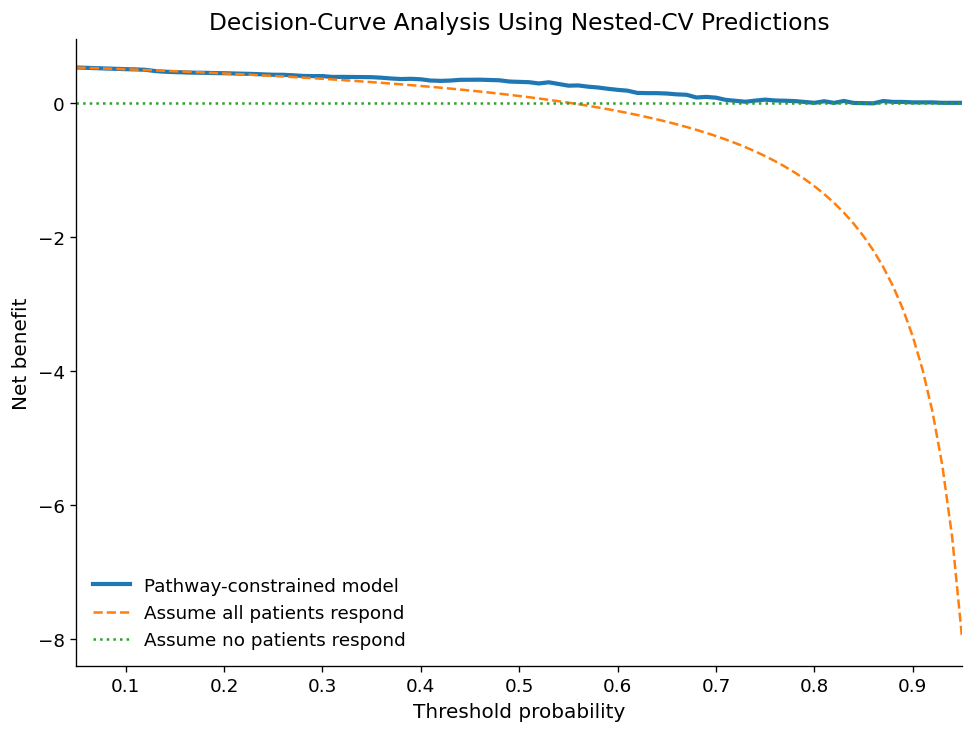

Full pathway model repeated-CV AUROC: 0.792
Predictions received per patient: [5]
[01/14] Removed: Angiogenesis | AUROC: 0.797 | Loss: -0.004
[02/14] Removed: Apoptosis | AUROC: 0.794 | Loss: -0.002
[03/14] Removed: Complement | AUROC: 0.794 | Loss: -0.001
[04/14] Removed: DNA repair | AUROC: 0.792 | Loss: +0.000
[05/14] Removed: E2F targets | AUROC: 0.793 | Loss: -0.001
[06/14] Removed: Epithelial-mesenchymal transition | AUROC: 0.790 | Loss: +0.002
[07/14] Removed: G2M checkpoint | AUROC: 0.796 | Loss: -0.004
[08/14] Removed: Glycolysis | AUROC: 0.779 | Loss: +0.013
[09/14] Removed: Hypoxia | AUROC: 0.783 | Loss: +0.009
[10/14] Removed: IL6-JAK-STAT3 signaling | AUROC: 0.792 | Loss: +0.001
[11/14] Removed: Inflammatory response | AUROC: 0.793 | Loss: -0.001
[12/14] Removed: Oxidative phosphorylation | AUROC: 0.786 | Loss: +0.006
[13/14] Removed: TNF-alpha/NF-kB signaling | AUROC: 0.794 | Loss: -0.001
[14/14] Removed: p53 pathway | AUROC: 0.783 | Loss: +0.009


,removed_pathway,full_model_auc,reduced_model_auc,auc_change_after_removal,performance_loss_when_removed
0,Glycolysis,0.792368,0.778900,-0.013468,0.013468
1,p53 pathway,0.792368,0.783202,-0.009166,0.009166
2,Hypoxia,0.792368,0.783202,-0.009166,0.009166
3,Oxidative phosphorylation,0.792368,0.786195,-0.006173,0.006173
4,Epithelial-mesenchymal transition,0.792368,0.789936,-0.002432,0.002432
5,IL6-JAK-STAT3 signaling,0.792368,0.791807,-0.000561,0.000561
6,DNA repair,0.792368,0.792181,-0.000187,0.000187
7,E2F targets,0.792368,0.793116,0.000748,-0.000748
8,Inflammatory response,0.792368,0.793490,0.001122,-0.001122
9,TNF-alpha/NF-kB signaling,0.792368,0.793678,0.001309,-0.001309


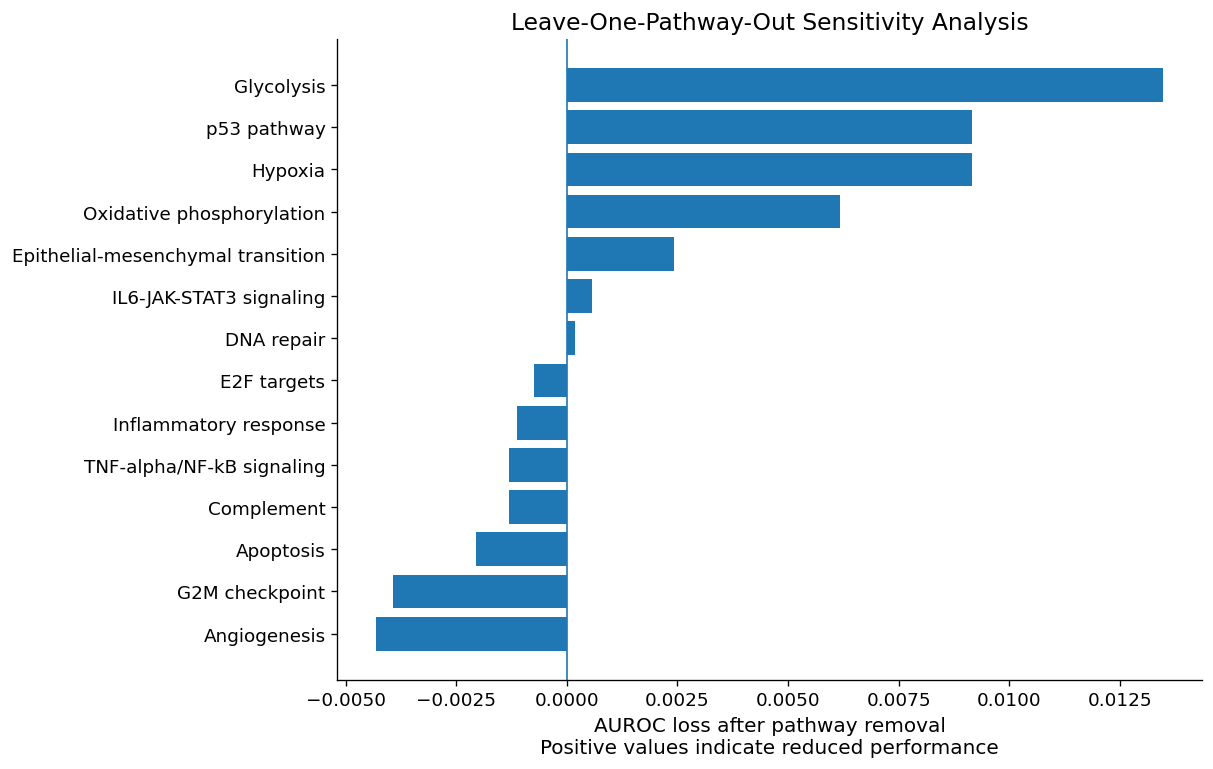


CELL 17 COMPLETED SUCCESSFULLY.


In [39]:
# CELL 17 — DECISION-CURVE AND LEAVE-ONE-PATHWAY-OUT ANALYSIS
# FIXED VERSION FOR REPEATED CROSS-VALIDATION

# ============================================================
# 17A. DECISION-CURVE ANALYSIS
# ============================================================

def calculate_net_benefit(y_true, probabilities, threshold):
    """
    Calculate decision-curve net benefit at one probability threshold.
    """
    y_true = np.asarray(y_true).astype(int)
    probabilities = np.asarray(probabilities, dtype=float)

    predicted_positive = probabilities >= threshold

    true_positive = np.sum(
        (predicted_positive == 1) & (y_true == 1)
    )

    false_positive = np.sum(
        (predicted_positive == 1) & (y_true == 0)
    )

    n_samples = len(y_true)

    return (
        true_positive / n_samples
        - false_positive / n_samples
        * threshold / (1.0 - threshold)
    )


thresholds = np.arange(0.05, 0.96, 0.01)

model_net_benefit = np.array([
    calculate_net_benefit(
        observed,
        predicted,
        threshold
    )
    for threshold in thresholds
])

response_prevalence = float(np.mean(observed))

treat_all_net_benefit = (
    response_prevalence
    - (1.0 - response_prevalence)
    * thresholds / (1.0 - thresholds)
)

treat_none_net_benefit = np.zeros_like(thresholds)

decision_curve = pd.DataFrame({
    "threshold_probability": thresholds,
    "model_net_benefit": model_net_benefit,
    "treat_all_net_benefit": treat_all_net_benefit,
    "treat_none_net_benefit": treat_none_net_benefit
})

decision_curve.to_csv(
    RESULTS_DIR / "Decision_Curve_Data.csv",
    index=False
)

fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(
    thresholds,
    model_net_benefit,
    linewidth=2.5,
    label="Pathway-constrained model"
)

ax.plot(
    thresholds,
    treat_all_net_benefit,
    linestyle="--",
    label="Assume all patients respond"
)

ax.plot(
    thresholds,
    treat_none_net_benefit,
    linestyle=":",
    label="Assume no patients respond"
)

ax.set_xlim(0.05, 0.95)
ax.set_xlabel("Threshold probability")
ax.set_ylabel("Net benefit")
ax.set_title(
    "Decision-Curve Analysis Using Nested-CV Predictions"
)

ax.legend(frameon=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.savefig(
    FIGURES_DIR / "Figure_13_Decision_Curve.jpg",
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 17B. HELPER FUNCTION FOR REPEATED CV PREDICTIONS
# ============================================================

def repeated_cv_probabilities(
    estimator,
    X_data,
    y_data,
    n_splits=5,
    n_repeats=5,
    random_state=42
):
    """
    Generate patient-level probabilities from repeated stratified CV.

    Every patient receives one out-of-fold prediction per repetition.
    Predictions are subsequently averaged for each patient.
    """
    X_data = X_data.copy()
    y_data = pd.Series(
        np.asarray(y_data).astype(int),
        index=X_data.index
    )

    repeated_cv = RepeatedStratifiedKFold(
        n_splits=n_splits,
        n_repeats=n_repeats,
        random_state=random_state
    )

    prediction_sum = np.zeros(len(X_data), dtype=float)
    prediction_count = np.zeros(len(X_data), dtype=int)

    for fold_number, (train_index, test_index) in enumerate(
        repeated_cv.split(X_data, y_data),
        start=1
    ):
        fold_model = clone(estimator)

        fold_model.fit(
            X_data.iloc[train_index],
            y_data.iloc[train_index]
        )

        fold_probability = fold_model.predict_proba(
            X_data.iloc[test_index]
        )[:, 1]

        prediction_sum[test_index] += fold_probability
        prediction_count[test_index] += 1

    if np.any(prediction_count == 0):
        raise RuntimeError(
            "At least one sample did not receive an "
            "out-of-fold prediction."
        )

    if not np.all(prediction_count == n_repeats):
        raise RuntimeError(
            "Unexpected prediction count per sample. "
            f"Observed range: {prediction_count.min()}–"
            f"{prediction_count.max()}."
        )

    averaged_probability = (
        prediction_sum / prediction_count
    )

    return averaged_probability, prediction_count


# ============================================================
# 17C. FULL-MODEL REPEATED-CV PERFORMANCE
# ============================================================

full_probabilities, full_prediction_counts = (
    repeated_cv_probabilities(
        estimator=fixed_model,
        X_data=X,
        y_data=y,
        n_splits=5,
        n_repeats=5,
        random_state=RANDOM_STATE
    )
)

full_auc = roc_auc_score(
    y,
    full_probabilities
)

print(
    f"Full pathway model repeated-CV AUROC: "
    f"{full_auc:.3f}"
)

print(
    "Predictions received per patient:",
    np.unique(full_prediction_counts)
)


# ============================================================
# 17D. LEAVE-ONE-PATHWAY-OUT ANALYSIS
# ============================================================

leave_one_out_rows = []

for pathway_number, pathway in enumerate(
    X.columns,
    start=1
):
    reduced_X = X.drop(columns=[pathway])

    reduced_probabilities, reduced_prediction_counts = (
        repeated_cv_probabilities(
            estimator=fixed_model,
            X_data=reduced_X,
            y_data=y,
            n_splits=5,
            n_repeats=5,
            random_state=RANDOM_STATE
        )
    )

    reduced_auc = roc_auc_score(
        y,
        reduced_probabilities
    )

    leave_one_out_rows.append({
        "removed_pathway": pathway,
        "full_model_auc": full_auc,
        "reduced_model_auc": reduced_auc,
        "auc_change_after_removal":
            reduced_auc - full_auc,
        "performance_loss_when_removed":
            full_auc - reduced_auc
    })

    print(
        f"[{pathway_number:02d}/{X.shape[1]:02d}] "
        f"Removed: {pathway} | "
        f"AUROC: {reduced_auc:.3f} | "
        f"Loss: {full_auc - reduced_auc:+.3f}"
    )


leave_one_out = pd.DataFrame(
    leave_one_out_rows
).sort_values(
    "performance_loss_when_removed",
    ascending=False
).reset_index(drop=True)

leave_one_out.to_csv(
    RESULTS_DIR /
    "Leave_One_Pathway_Out_Sensitivity.csv",
    index=False
)

display(leave_one_out)


# ============================================================
# 17E. LEAVE-ONE-PATHWAY-OUT FIGURE
# ============================================================

plot_data = leave_one_out.sort_values(
    "performance_loss_when_removed",
    ascending=True
)

fig_height = max(
    6,
    0.45 * len(plot_data)
)

fig, ax = plt.subplots(
    figsize=(10, fig_height)
)

positions = np.arange(len(plot_data))

ax.barh(
    positions,
    plot_data["performance_loss_when_removed"]
)

ax.axvline(
    0,
    linewidth=1
)

ax.set_yticks(positions)
ax.set_yticklabels(
    plot_data["removed_pathway"]
)

ax.set_xlabel(
    "AUROC loss after pathway removal\n"
    "Positive values indicate reduced performance"
)

ax.set_title(
    "Leave-One-Pathway-Out Sensitivity Analysis"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.savefig(
    FIGURES_DIR /
    "Figure_14_Leave_One_Pathway_Out.jpg",
    bbox_inches="tight"
)

plt.show()

print("\nCELL 17 COMPLETED SUCCESSFULLY.")

PATIENT-LEVEL RESPONSE STRATIFICATION


,probability_stratum,n,responders,observed_response_rate,median_predicted_probability,minimum_predicted_probability,maximum_predicted_probability,nonresponders
0,Low predicted response,49,11,0.224490,0.257547,0.035385,0.382750,38
1,Intermediate predicted response,49,31,0.632653,0.541806,0.383912,0.635232,18
2,High predicted response,49,39,0.795918,0.764158,0.653004,0.924809,10



Probability-stratum versus observed-response chi-square P = 3.534e-08


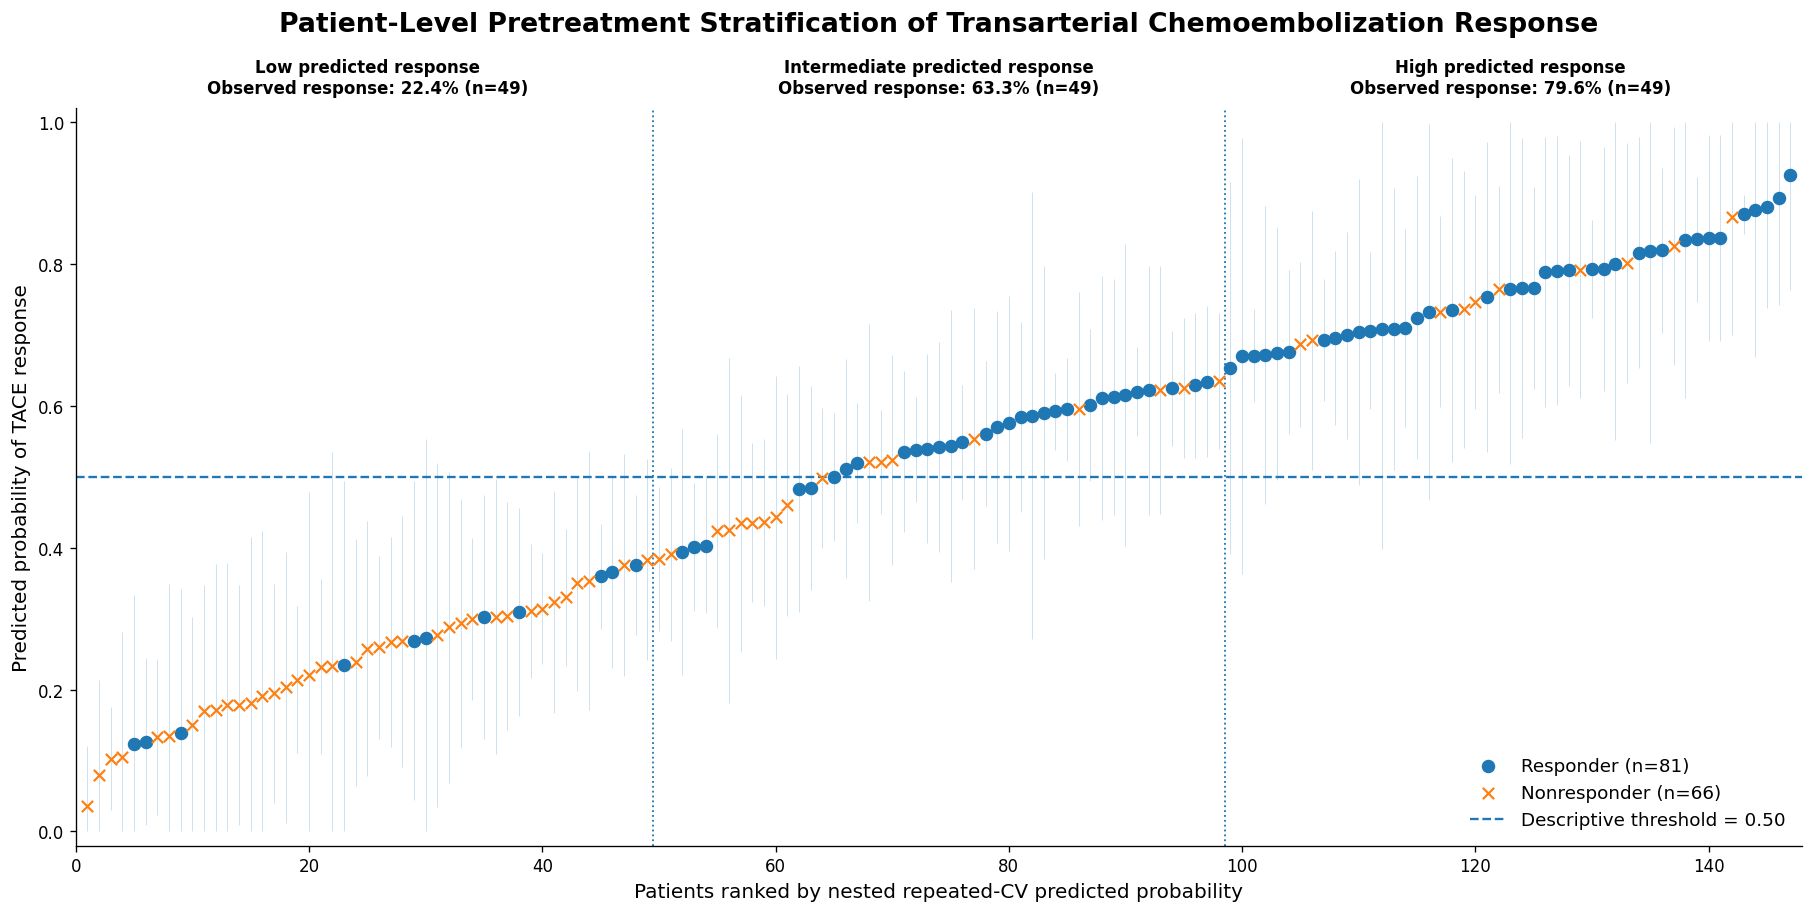


CELL 18 SUMMARY
Patients visualized: 147
Prediction repetitions per patient: [10]
Probability-stratum association P: 3.534e-08

Files saved:
  /Users/rifaldyfajar/IGET2026_GSE104580/results/Patient_Level_OOF_Response_Stratification.csv
  /Users/rifaldyfajar/IGET2026_GSE104580/results/Predicted_Response_Stratum_Summary.csv
  /Users/rifaldyfajar/IGET2026_GSE104580/figures/Figure_15_Patient_Level_OOF_Probability_Waterfall.jpg
  /Users/rifaldyfajar/IGET2026_GSE104580/figures/Figure_15_Patient_Level_OOF_Probability_Waterfall.png

Interpretation boundary:
The tertiles are descriptive risk strata and must not be described as prospectively validated clinical cutoffs.

✓ CELL 18 COMPLETED SUCCESSFULLY.


In [43]:
# CELL 18 — PATIENT-LEVEL OOF RESPONSE PROBABILITY WATERFALL
# Additional clinically interpretable result figure for IGET 2026

# ============================================================
# 18A. PREPARE PATIENT-LEVEL OUT-OF-FOLD PREDICTIONS
# ============================================================

waterfall_df = (
    oof_predictions[
        [
            "observed_response",
            "predicted_probability",
            "prediction_sd",
            "number_of_predictions"
        ]
    ]
    .copy()
)

waterfall_df.index.name = "sample_id"

# Scientific integrity checks.
assert waterfall_df.index.equals(metadata.index), (
    "OOF predictions are not aligned with sample metadata."
)

assert waterfall_df["predicted_probability"].between(0, 1).all(), (
    "Predicted probabilities must lie between 0 and 1."
)

assert waterfall_df["prediction_sd"].notna().all(), (
    "Prediction uncertainty contains missing values."
)

assert waterfall_df["number_of_predictions"].min() == 10, (
    "Each patient should have exactly 10 outer-CV predictions."
)

assert waterfall_df["number_of_predictions"].max() == 10, (
    "Each patient should have exactly 10 outer-CV predictions."
)

# Add readable observed outcome.
waterfall_df["observed_outcome"] = np.where(
    waterfall_df["observed_response"] == 1,
    "Responder",
    "Nonresponder"
)

# Sort patients from lowest to highest predicted probability.
waterfall_df = waterfall_df.sort_values(
    "predicted_probability",
    ascending=True
)

waterfall_df["patient_rank"] = np.arange(
    1,
    len(waterfall_df) + 1
)

# Approximate 95% uncertainty interval across the repeated
# out-of-fold predictions.
waterfall_df["probability_ci_lower"] = np.clip(
    waterfall_df["predicted_probability"]
    - 1.96 * waterfall_df["prediction_sd"],
    0,
    1
)

waterfall_df["probability_ci_upper"] = np.clip(
    waterfall_df["predicted_probability"]
    + 1.96 * waterfall_df["prediction_sd"],
    0,
    1
)


# ============================================================
# 18B. CREATE THREE PRE-SPECIFIED PROBABILITY STRATA
# ============================================================

# Tertiles are used only for descriptive stratification.
# They are not presented as validated clinical cutoffs.
waterfall_df["probability_stratum"] = pd.qcut(
    waterfall_df["predicted_probability"],
    q=3,
    labels=[
        "Low predicted response",
        "Intermediate predicted response",
        "High predicted response"
    ]
)

stratum_summary = (
    waterfall_df
    .groupby(
        "probability_stratum",
        observed=True
    )
    .agg(
        n=("observed_response", "size"),
        responders=("observed_response", "sum"),
        observed_response_rate=("observed_response", "mean"),
        median_predicted_probability=(
            "predicted_probability",
            "median"
        ),
        minimum_predicted_probability=(
            "predicted_probability",
            "min"
        ),
        maximum_predicted_probability=(
            "predicted_probability",
            "max"
        )
    )
    .reset_index()
)

stratum_summary["nonresponders"] = (
    stratum_summary["n"]
    - stratum_summary["responders"]
)

# Fisher–Freeman–Halton-style exact testing is not directly
# available in scipy for a 3 × 2 table. Use chi-square as a
# descriptive global association test.
stratum_contingency = pd.crosstab(
    waterfall_df["probability_stratum"],
    waterfall_df["observed_outcome"]
)

stratum_chi2, stratum_p_value, _, _ = chi2_contingency(
    stratum_contingency
)

print("PATIENT-LEVEL RESPONSE STRATIFICATION")
print("=" * 55)

display(stratum_summary)

print(
    "\nProbability-stratum versus observed-response "
    f"chi-square P = {stratum_p_value:.6g}"
)


# ============================================================
# 18C. PATIENT-LEVEL WATERFALL FIGURE
# ============================================================

fig, ax = plt.subplots(
    figsize=(15, 7.5)
)

# Uncertainty intervals for each patient.
ax.vlines(
    x=waterfall_df["patient_rank"],
    ymin=waterfall_df["probability_ci_lower"],
    ymax=waterfall_df["probability_ci_upper"],
    linewidth=0.55,
    alpha=0.24
)

# Plot responders and nonresponders separately.
for outcome_name, marker_shape in [
    ("Responder", "o"),
    ("Nonresponder", "x")
]:
    subset = waterfall_df[
        waterfall_df["observed_outcome"] == outcome_name
    ]

    ax.scatter(
        subset["patient_rank"],
        subset["predicted_probability"],
        marker=marker_shape,
        s=46,
        linewidth=1.3,
        label=(
            f"{outcome_name} "
            f"(n={len(subset)})"
        ),
        zorder=3
    )

# Classification threshold used in the descriptive metrics.
ax.axhline(
    y=0.50,
    linestyle="--",
    linewidth=1.4,
    label="Descriptive threshold = 0.50"
)

# Tertile boundaries.
low_boundary = int(
    (
        waterfall_df["probability_stratum"]
        == "Low predicted response"
    ).sum()
)

intermediate_boundary = low_boundary + int(
    (
        waterfall_df["probability_stratum"]
        == "Intermediate predicted response"
    ).sum()
)

ax.axvline(
    low_boundary + 0.5,
    linestyle=":",
    linewidth=1.1
)

ax.axvline(
    intermediate_boundary + 0.5,
    linestyle=":",
    linewidth=1.1
)

# Add observed response rates for each stratum.
stratum_position_ranges = {
    "Low predicted response": (
        1,
        low_boundary
    ),
    "Intermediate predicted response": (
        low_boundary + 1,
        intermediate_boundary
    ),
    "High predicted response": (
        intermediate_boundary + 1,
        len(waterfall_df)
    )
}

for _, row in stratum_summary.iterrows():

    stratum_name = str(
        row["probability_stratum"]
    )

    start_position, end_position = (
        stratum_position_ranges[stratum_name]
    )

    middle_position = (
        start_position + end_position
    ) / 2

    ax.text(
        middle_position,
        1.035,
        (
            f"{stratum_name}\n"
            f"Observed response: "
            f"{row['observed_response_rate']:.1%} "
            f"(n={int(row['n'])})"
        ),
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
        clip_on=False
    )

ax.set_xlim(
    0,
    len(waterfall_df) + 1
)

ax.set_ylim(
    -0.02,
    1.02
)

ax.set_xlabel(
    "Patients ranked by nested repeated-CV predicted probability",
    fontsize=12
)

ax.set_ylabel(
    "Predicted probability of TACE response",
    fontsize=12
)

ax.set_title(
    "Patient-Level Pretreatment Stratification of "
    "Transarterial Chemoembolization Response",
    fontsize=16,
    fontweight="bold",
    pad=46
)

ax.legend(
    frameon=False,
    loc="lower right"
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(
    axis="both",
    labelsize=10
)

fig.subplots_adjust(
    top=0.78,
    bottom=0.15,
    left=0.09,
    right=0.98
)

waterfall_jpg_path = (
    FIGURES_DIR
    / "Figure_15_Patient_Level_OOF_Probability_Waterfall.jpg"
)

waterfall_png_path = (
    FIGURES_DIR
    / "Figure_15_Patient_Level_OOF_Probability_Waterfall.png"
)

fig.savefig(
    waterfall_jpg_path,
    dpi=600,
    bbox_inches="tight"
)

fig.savefig(
    waterfall_png_path,
    dpi=600,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# 18D. EXPORT PATIENT-LEVEL AND STRATUM RESULTS
# ============================================================

waterfall_df.to_csv(
    RESULTS_DIR
    / "Patient_Level_OOF_Response_Stratification.csv"
)

stratum_summary.to_csv(
    RESULTS_DIR
    / "Predicted_Response_Stratum_Summary.csv",
    index=False
)

stratum_contingency.to_csv(
    RESULTS_DIR
    / "Predicted_Response_Stratum_Contingency.csv"
)

print("\nCELL 18 SUMMARY")
print("=" * 55)

print(
    "Patients visualized:",
    len(waterfall_df)
)

print(
    "Prediction repetitions per patient:",
    waterfall_df["number_of_predictions"].unique()
)

print(
    "Probability-stratum association P:",
    f"{stratum_p_value:.6g}"
)

print("\nFiles saved:")
print(
    " ",
    RESULTS_DIR
    / "Patient_Level_OOF_Response_Stratification.csv"
)

print(
    " ",
    RESULTS_DIR
    / "Predicted_Response_Stratum_Summary.csv"
)

print(
    " ",
    waterfall_jpg_path
)

print(
    " ",
    waterfall_png_path
)

print(
    "\nInterpretation boundary:"
)

print(
    "The tertiles are descriptive risk strata and must not "
    "be described as prospectively validated clinical cutoffs."
)

print("\n✓ CELL 18 COMPLETED SUCCESSFULLY.")

In [52]:
# CELL 19 — FINAL EXPORT AND AUTOMATIC RESEARCH SUMMARY

output_workbook = RESULTS_DIR / "IGET2026_GSE104580_Complete_Results.xlsx"

with pd.ExcelWriter(
    output_workbook,
    engine="openpyxl"
) as writer:

    metadata.to_excel(
        writer,
        sheet_name="Sample_Metadata"
    )

    pathway_scores.to_excel(
        writer,
        sheet_name="Pathway_Scores"
    )

    pathway_association.to_excel(
        writer,
        sheet_name="Pathway_Associations",
        index=False
    )

    endotype_selection.to_excel(
        writer,
        sheet_name="Endotype_Selection",
        index=False
    )

    endotype_df.to_excel(
        writer,
        sheet_name="Endotype_Assignments"
    )

    endotype_profile.to_excel(
        writer,
        sheet_name="Endotype_Profiles"
    )

    endotype_response_summary.to_excel(
        writer,
        sheet_name="Endotype_Response"
    )

    fold_performance.to_excel(
        writer,
        sheet_name="Outer_Fold_Performance",
        index=False
    )

    oof_predictions.to_excel(
        writer,
        sheet_name="OOF_Predictions"
    )

    performance_summary.to_excel(
        writer,
        sheet_name="Model_Performance",
        index=False
    )

    coefficient_df.to_excel(
        writer,
        sheet_name="Model_Coefficients",
        index=False
    )

    permutation_summary.to_excel(
        writer,
        sheet_name="Permutation_Test",
        index=False
    )

    leave_one_out.to_excel(
        writer,
        sheet_name="LOPO_Sensitivity",
        index=False
    )

    decision_curve.to_excel(
        writer,
        sheet_name="Decision_Curve",
        index=False
    )


most_nonresponse_associated = (
    pathway_association
    .sort_values("rank_biserial_correlation")
    .iloc[0]
)

most_response_associated = (
    pathway_association
    .sort_values("rank_biserial_correlation", ascending=False)
    .iloc[0]
)

lowest_response_endotype = (
    endotype_response_summary
    .sort_values("response_rate")
    .iloc[0]
)

highest_response_endotype = (
    endotype_response_summary
    .sort_values("response_rate", ascending=False)
    .iloc[0]
)

summary_text = f"""
IGET 2026 — GSE104580 PROJECT SUMMARY
=====================================

Dataset
-------
GEO accession: {GSE_ID}
Platform: {GPL_ID}
Pretreatment HCC tumor samples: {len(metadata)}
TACE responders: {int(y.sum())}
TACE nonresponders: {int(len(y) - y.sum())}
Gene-level features after annotation: {expression_gene.shape[0]}
Mechanistic pathway features: {pathway_scores.shape[1]}

Study concept
-------------
Pathway-constrained machine learning and unsupervised biological
endotyping of pretreatment tumor transcriptomics associated with
response to transarterial chemoembolization.

Biological endotypes
--------------------
Selected number of endotypes: {selected_k}
Endotype-response association P value: {chi2_p:.6g}

Lowest observed response endotype:
{lowest_response_endotype.name}
Response rate: {lowest_response_endotype['response_rate']:.3f}
Sample size: {int(lowest_response_endotype['n'])}

Highest observed response endotype:
{highest_response_endotype.name}
Response rate: {highest_response_endotype['response_rate']:.3f}
Sample size: {int(highest_response_endotype['n'])}

Pathway associations
--------------------
Strongest nonresponse-associated pathway:
{most_nonresponse_associated['pathway']}
Rank-biserial correlation:
{most_nonresponse_associated['rank_biserial_correlation']:.3f}
FDR:
{most_nonresponse_associated['fdr']:.6g}

Strongest response-associated pathway:
{most_response_associated['pathway']}
Rank-biserial correlation:
{most_response_associated['rank_biserial_correlation']:.3f}
FDR:
{most_response_associated['fdr']:.6g}

Machine-learning performance
----------------------------
Nested repeated-CV AUROC:
{roc_auc:.3f} (95% CI {roc_ci[0]:.3f}–{roc_ci[1]:.3f})

Nested repeated-CV AUPRC:
{average_precision:.3f} (95% CI {ap_ci[0]:.3f}–{ap_ci[1]:.3f})

Response prevalence:
{prevalence:.3f}

Brier score:
{brier:.3f}

Calibration intercept:
{calibration_intercept:.3f}

Calibration slope:
{calibration_slope:.3f}

Sensitivity at threshold 0.50:
{sensitivity:.3f}

Specificity at threshold 0.50:
{specificity:.3f}

Balanced accuracy at threshold 0.50:
{balanced_accuracy:.3f}

Permutation test
----------------
Observed five-fold CV AUROC:
{observed_cv_score:.3f}

Mean permuted AUROC:
{permutation_scores.mean():.3f}

Permutation P value:
{permutation_p_value:.6g}

waterfall_df.to_excel(
    writer,
    sheet_name="Patient_Waterfall"
)

stratum_summary.to_excel(
    writer,
    sheet_name="Response_Strata",
    index=False
)

stratum_contingency.to_excel(
    writer,
    sheet_name="Strata_Contingency"
)

Final model
-----------
Algorithm:
Elastic-net logistic regression

Final C:
{best_C}

Final l1 ratio:
{best_l1_ratio}

Interpretive boundary
---------------------
This is a retrospective, single-cohort, hypothesis-generating
transcriptomic study. It does not establish prospective clinical
utility and must not be described as externally validated.
"""

summary_path = RESULTS_DIR / "IGET2026_Research_Summary.txt"
summary_path.write_text(summary_text)

print(summary_text)

print("\nFILES CREATED")
print("=============")
print("Complete workbook:", output_workbook)
print("Research summary:", summary_path)
print("Final model:", MODELS_DIR / "Final_Pathway_ElasticNet_Model.joblib")
print("Figures directory:", FIGURES_DIR)
print("\nANALYSIS COMPLETED SUCCESSFULLY.")


IGET 2026 — GSE104580 PROJECT SUMMARY

Dataset
-------
GEO accession: GSE104580
Platform: GPL570
Pretreatment HCC tumor samples: 147
TACE responders: 81
TACE nonresponders: 66
Gene-level features after annotation: 22878
Mechanistic pathway features: 14

Study concept
-------------
Pathway-constrained machine learning and unsupervised biological
endotyping of pretreatment tumor transcriptomics associated with
response to transarterial chemoembolization.

Biological endotypes
--------------------
Selected number of endotypes: 2
Endotype-response association P value: 0.146325

Lowest observed response endotype:
E1: TNF-alpha/NF-kB signaling / Apoptosis
Response rate: 0.487
Sample size: 76

Highest observed response endotype:
E2: Oxidative phosphorylation / DNA repair
Response rate: 0.620
Sample size: 71

Pathway associations
--------------------
Strongest nonresponse-associated pathway:
Glycolysis
Rank-biserial correlation:
-0.545
FDR:
1.97302e-07

Strongest response-associated pathway:
